# Projeto: predição de churn em telecom (dataset Cell2Cell, Duke/Teradata) Base: 51.047 clientes, 58 variáveis, churn de 28,82%

In [7]:
# Bibliotecas básicas
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Dataset
import kagglehub

# Estatística
from scipy import stats

In [8]:
# Baixando o dataset do Kaggle
path = kagglehub.dataset_download("jpacse/datasets-for-churn-telecom")

df = pd.read_csv(
    os.path.join(path, "cell2celltrain.csv")
)

In [9]:
df.head(100)

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,...,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,...,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,...,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,...,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,...,0,9,No,1,10,No,1-Highest,Other,Professional,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,3000646,No,108.72,1228.0,108.0,0.74,0.0,0.0,-12.0,-0.7,...,0,4,No,0,150,No,1-Highest,Other,Other,Yes
96,3000654,No,32.27,112.0,32.0,0.00,0.0,0.0,-2.0,-0.3,...,0,4,No,1,30,No,1-Highest,Other,Other,Yes
97,3000674,No,43.72,245.0,30.0,0.00,30.0,0.0,53.0,7.0,...,0,3,No,0,150,No,1-Highest,Other,Other,No
98,3000678,No,65.94,572.0,59.0,0.00,45.0,1.5,-119.0,-15.6,...,0,0,No,1,80,No,3-Good,Other,Other,Unknown


In [10]:
# Informações gerais sobre o dataset
print("=== INFORMAÇÕES GERAIS DO DATASET ===\n")
print(df.info())

print("\n=== ESTATÍSTICAS DESCRITIVAS ===\n")
df.describe()

=== INFORMAÇÕES GERAIS DO DATASET ===

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51047 entries, 0 to 51046
Data columns (total 58 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 51047 non-null  int64  
 1   Churn                      51047 non-null  object 
 2   MonthlyRevenue             50891 non-null  float64
 3   MonthlyMinutes             50891 non-null  float64
 4   TotalRecurringCharge       50891 non-null  float64
 5   DirectorAssistedCalls      50891 non-null  float64
 6   OverageMinutes             50891 non-null  float64
 7   RoamingCalls               50891 non-null  float64
 8   PercChangeMinutes          50680 non-null  float64
 9   PercChangeRevenues         50680 non-null  float64
 10  DroppedCalls               51047 non-null  float64
 11  BlockedCalls               51047 non-null  float64
 12  UnansweredCalls            51047 non-null  float64
 13  Custome

,CustomerID,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,...,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,RetentionCalls,RetentionOffersAccepted,ReferralsMadeBySubscriber,IncomeGroup,AdjustmentsToCreditRating
count,5.104700e+04,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50891.000000,50680.000000,50680.000000,51047.000000,...,51046.000000,51046.000000,51046.000000,50138.000000,50138.000000,51047.000000,51047.000000,51047.000000,51047.000000,51047.000000
mean,3.201957e+06,58.834492,525.653416,46.830088,0.895229,40.027785,1.236244,-11.547908,-1.191985,6.011489,...,1.805646,1.558751,380.545841,31.338127,21.144142,0.037201,0.018277,0.052070,4.324524,0.053911
std,1.169056e+05,44.507336,529.871063,23.848871,2.228546,96.588076,9.818294,257.514772,39.574915,9.043955,...,1.331173,0.905932,253.801982,22.094635,23.931368,0.206483,0.142458,0.307592,3.138236,0.383147
min,3.000002e+06,-6.170000,0.000000,-11.000000,0.000000,0.000000,0.000000,-3875.000000,-1107.700000,0.000000,...,1.000000,1.000000,-5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.100632e+06,33.610000,158.000000,30.000000,0.000000,0.000000,0.000000,-83.000000,-7.100000,0.700000,...,1.000000,1.000000,205.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.201534e+06,48.460000,366.000000,45.000000,0.250000,3.000000,0.000000,-5.000000,-0.300000,3.000000,...,1.000000,1.000000,329.000000,36.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000
75%,3.305376e+06,71.065000,723.000000,60.000000,0.990000,41.000000,0.300000,66.000000,1.600000,7.700000,...,2.000000,2.000000,515.000000,48.000000,42.000000,0.000000,0.000000,0.000000,7.000000,0.000000
max,3.399994e+06,1223.380000,7359.000000,400.000000,159.390000,4321.000000,1112.400000,5192.000000,2483.500000,221.700000,...,24.000000,15.000000,1812.000000,99.000000,99.000000,4.000000,3.000000,35.000000,9.000000,25.000000


## Esquema das variáveis

> Descrições baseadas na documentação do Kaggle e revisadas para refletir os valores reais
> encontrados no dataset.

1. **CustomerID:** Um identificador único para cada cliente.

2. **Churn:** Indica se o cliente cancelou o serviço (`Yes` = cancelou, `No` = não cancelou).

3. **MonthlyRevenue:** O valor que o cliente paga mensalmente pelo serviço de telefonia móvel.
   Há registros com valores negativos (mínimo de -6,17), provavelmente estornos ou créditos.

4. **MonthlyMinutes:** O número de minutos que o cliente utiliza por mês.

5. **TotalRecurringCharge:** O valor total cobrado do cliente mensalmente, incluindo cobranças e tarifas recorrentes.

6. **DirectorAssistedCalls:** Média mensal de chamadas realizadas pelo cliente com auxílio de operador.

7. **OverageMinutes:** O número de minutos utilizados pelo cliente além dos minutos incluídos em seu plano mensal.

8. **RoamingCalls:** Média mensal de chamadas realizadas em roaming, fora da área local.

9. **PercChangeMinutes:** Variação no uso de minutos em relação ao período anterior. Apesar do nome,
   os valores são absolutos (em minutos), e não percentuais.

10. **PercChangeRevenues:** Variação na receita em relação ao período anterior. Apesar do nome, os
    valores são absolutos (em valor monetário), e não percentuais.

11. **DroppedCalls:** Média mensal de chamadas interrompidas pela rede.

12. **BlockedCalls:** Média mensal de chamadas bloqueadas por congestionamento da rede ou outros problemas.

13. **UnansweredCalls:** Média mensal de chamadas não atendidas.

14. **CustomerCareCalls:** Média mensal de chamadas do cliente ao atendimento/suporte.

15. **ThreewayCalls:** Média mensal de chamadas com três participantes.

16. **ReceivedCalls:** Média mensal de chamadas recebidas pelo cliente.

17. **OutboundCalls:** Média mensal de chamadas realizadas pelo cliente.

18. **InboundCalls:** Média mensal de chamadas recebidas pelo cliente de outras pessoas.

19. **PeakCallsInOut:** Média mensal de chamadas realizadas ou recebidas em horário de pico.

20. **OffPeakCallsInOut:** Média mensal de chamadas realizadas ou recebidas fora do horário de pico.

21. **DroppedBlockedCalls:** Média mensal de chamadas interrompidas ou bloqueadas
    (corresponde à soma de `DroppedCalls` e `BlockedCalls`).

22. **CallForwardingCalls:** Média mensal de chamadas encaminhadas para outro número.

23. **CallWaitingCalls:** Média mensal de chamadas que utilizaram o recurso de chamada em espera.

24. **MonthsInService:** O número de meses em que o cliente está inscrito no serviço.

25. **UniqueSubs:** O número de assinantes distintos associados à conta do cliente.

26. **ActiveSubs:** O número de assinantes ativos associados à conta do cliente.

27. **ServiceArea:** A área geográfica onde o cliente está localizado.

28. **Handsets:** O número de aparelhos celulares associados à conta do cliente.

29. **HandsetModels:** O número de modelos diferentes de aparelhos celulares associados à conta do cliente.

30. **CurrentEquipmentDays:** O número de dias que o cliente possui seu equipamento atual.
    Há 76 registros com valores negativos, o que indica provável erro de registro.

31. **AgeHH1:** A idade do primeiro responsável pelo domicílio. O valor 0 indica idade não informada.

32. **AgeHH2:** A idade do segundo responsável pelo domicílio. O valor 0 indica idade não informada
    ou ausência de segundo responsável.

33. **ChildrenInHH:** Indica se há crianças no domicílio do cliente (`Yes`/`No`).

34. **HandsetRefurbished:** Indica se o aparelho celular do cliente é recondicionado (`Yes`/`No`).

35. **HandsetWebCapable:** Indica se o aparelho celular possui capacidade de acesso à internet (`Yes`/`No`).

36. **TruckOwner:** Indica se o cliente possui uma caminhonete/caminhão (`Yes`/`No`).

37. **RVOwner:** Indica se o cliente possui um veículo recreativo (RV) (`Yes`/`No`).

38. **Homeownership:** Indica se a informação sobre propriedade do imóvel é conhecida (`Known`/`Unknown`).

39. **BuysViaMailOrder:** Indica se o cliente compra produtos por meio de pedidos via correio (`Yes`/`No`).

40. **RespondsToMailOffers:** Indica se o cliente responde a ofertas enviadas pelo correio (`Yes`/`No`).

41. **OptOutMailings:** Indica se o cliente optou por não receber correspondências/ofertas (`Yes`/`No`).

42. **NonUSTravel:** Indica se o cliente viaja para fora dos Estados Unidos (`Yes`/`No`).

43. **OwnsComputer:** Indica se o cliente possui um computador (`Yes`/`No`).

44. **HasCreditCard:** Indica se o cliente possui cartão de crédito (`Yes`/`No`).

45. **RetentionCalls:** Número de chamadas feitas pelo cliente para a equipe de retenção (0 a 4).

46. **RetentionOffersAccepted:** Número de ofertas de retenção aceitas pelo cliente (0 a 3).

47. **NewCellphoneUser:** Indica se o cliente é um novo usuário de celular (`Yes`/`No`).

48. **NotNewCellphoneUser:** Indica se o cliente não é um novo usuário de celular (`Yes`/`No`).

49. **ReferralsMadeBySubscriber:** O número de indicações feitas pelo cliente.

50. **IncomeGroup:** Faixa de renda do cliente (0 a 9). O valor 0 provavelmente indica renda não informada.

51. **OwnsMotorcycle:** Indica se o cliente possui uma motocicleta (`Yes`/`No`).

52. **AdjustmentsToCreditRating:** O número de ajustes realizados na classificação de crédito do cliente.

53. **HandsetPrice:** O preço do aparelho celular associado à conta do cliente.

54. **MadeCallToRetentionTeam:** Indica se o cliente realizou uma chamada para a equipe de retenção (`Yes`/`No`).

55. **CreditRating:** A classificação de crédito do cliente.

56. **PrizmCode:** O código PRIZM do cliente, um sistema de segmentação utilizado para pesquisas e análises de consumidores.

57. **Occupation:** A ocupação/profissão do cliente.

58. **MaritalStatus:** O estado civil do cliente.

# Transformações de variáveis (codificação binária)
### 1. A coluna de "Churn" contém Yes/No. Precisamos converter para valores binários.

In [11]:
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

### 2. ** Outras variáveis Yes/No (15 colunas):**
`ChildrenInHH`, `HandsetRefurbished`, `HandsetWebCapable`,
   `TruckOwner`, `RVOwner`, `BuysViaMailOrder`, `RespondsToMailOffers`, `OptOutMailings`,
   `NonUSTravel`, `OwnsComputer`, `HasCreditCard`, `NewCellphoneUser`, `NotNewCellphoneUser`,
   `OwnsMotorcycle` e `MadeCallToRetentionTeam`. Todas devem ser convertidas para valores binários (`Yes` = 1 e `No` = 0).

In [12]:
# Identifica as colunas cujos únicos valores são 'Yes' e 'No' e transforma para binário
colunas_binarias = [
    col for col in df.select_dtypes(include=['object', 'string']).columns
    if set(df[col].dropna().unique()) <= {'Yes', 'No'}
]
print(f"{len(colunas_binarias)} colunas binárias encontradas:\n{colunas_binarias}")

df[colunas_binarias] = df[colunas_binarias].replace({'Yes': 1, 'No': 0}).astype(int)

15 colunas binárias encontradas:
['ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'NewCellphoneUser', 'NotNewCellphoneUser', 'OwnsMotorcycle', 'MadeCallToRetentionTeam']


3. **Homeownership:** os valores no dataset são `Known`/`Unknown`. A variável indica se a
   informação sobre propriedade do imóvel está disponível no cadastro. Convertemos `Known` para 1 (informação disponível) e `Unknown` para 0
   (informação ausente).

In [13]:
df['Homeownership'] = df['Homeownership'].map({'Known': 1, 'Unknown': 0})

### Análise da variável RetentionOffersAccepted

A variável `RetentionOffersAccepted` registra quantas ofertas de retenção o cliente aceitou (0 a 3).
Analisamos dois aspectos:
1. **Distribuição:** quantos clientes existem em cada valor;
2. **Relação com o churn:** se a taxa de cancelamento muda conforme o número de ofertas aceitas;

In [14]:
# Tabela resumo: clientes, churn e taxa por número de ofertas aceitas
analise_ofertas = df.groupby('RetentionOffersAccepted')['Churn'].agg(
    clientes='count', churn='sum', taxa_churn='mean'
)
analise_ofertas['perc_base'] = analise_ofertas['clientes'] / len(df) * 100
analise_ofertas['taxa_churn'] = analise_ofertas['taxa_churn'] * 100

analise_ofertas.round(2)

,clientes,churn,taxa_churn,perc_base
RetentionOffersAccepted,,,,
0,50166,14349,28.60,98.27
1,837,343,40.98,1.64
2,36,16,44.44,0.07
3,8,3,37.50,0.02


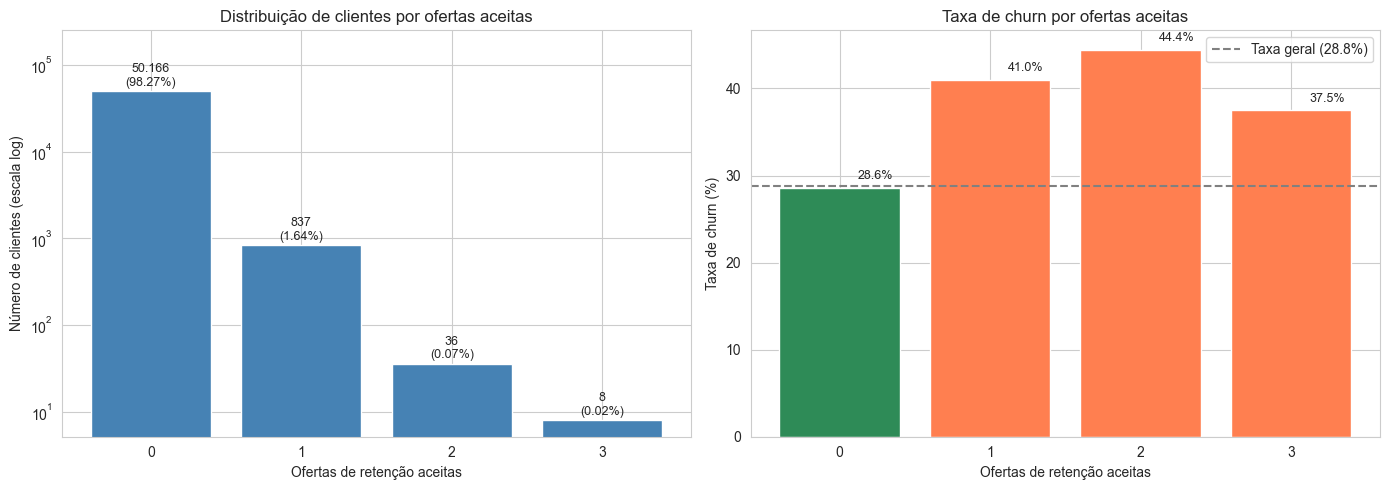

In [15]:
taxa_geral = df['Churn'].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: volume de clientes (escala log, pois o valor 0 domina a base)
axes[0].bar(analise_ofertas.index.astype(str), analise_ofertas['clientes'], color='steelblue')
axes[0].set_yscale('log')
axes[0].set_ylim(top=analise_ofertas['clientes'].max() * 5)
axes[0].set_xlabel('Ofertas de retenção aceitas')
axes[0].set_ylabel('Número de clientes (escala log)')
axes[0].set_title('Distribuição de clientes por ofertas aceitas')
for i, (n, p) in enumerate(zip(analise_ofertas['clientes'], analise_ofertas['perc_base'])):
    axes[0].text(i, n * 1.15, f'{n:,}\n({p:.2f}%)'.replace(',', '.'), ha='center', fontsize=9)

# Gráfico 2: taxa de churn por número de ofertas aceitas
axes[1].bar(analise_ofertas.index.astype(str), analise_ofertas['taxa_churn'],
            color=['seagreen', 'coral', 'coral', 'coral'])
axes[1].axhline(taxa_geral, color='gray', linestyle='--', label=f'Taxa geral ({taxa_geral:.1f}%)')
axes[1].set_xlabel('Ofertas de retenção aceitas')
axes[1].set_ylabel('Taxa de churn (%)')
axes[1].set_title('Taxa de churn por ofertas aceitas')
axes[1].legend()
for i, t in enumerate(analise_ofertas['taxa_churn']):
    axes[1].text(i + 0.12, t + 1, f'{t:.1f}%', ha='left', fontsize=9)

plt.tight_layout()
plt.show()

* À esquerda: o valor 0 concentra 98,27% da base, e os valores 2 e 3 quase não
existem.
* À direita: as barras de erro dos valores 2 e 3 são enormes. Esse é o argumento visual de que não há dados suficientes para confiar nessas taxas.

**Conclusões:**

- **Distribuição muito concentrada:** 98,27% dos clientes nunca aceitaram uma oferta de retenção.
  Os valores 2 e 3 somam apenas 44 clientes (0,09% da base).
- **Aceitar uma oferta está associado a maior churn:** clientes que aceitaram ao menos uma oferta
  têm taxa de cancelamento de 41,1%, contra 28,6% dos que não aceitaram nenhuma. Uma interpretação
  possível é que a oferta é feita justamente a clientes que já demonstraram intenção de sair, ou
  seja, ela sinaliza risco, mas nem sempre consegue reter.
- **Aceitar mais de uma oferta não aumenta o risco de forma consistente:** a taxa de churn é de
  41,0% para quem aceitou 1 oferta, 44,4% para 2 e 37,5% para 3, sem uma tendência clara de
  crescimento. Além disso, os grupos de 2 e 3 ofertas têm apenas 36 e 8 clientes; com tão poucos
  casos, a taxa pode mudar bastante com a saída ou permanência de um único cliente, o que torna
  esses valores pouco confiáveis para o modelo aprender.

4. **RetentionOffersAccepted:** a decisão é de converter `RetentionOffersAccepted` para binária (1 = aceitou ao menos uma oferta,
0 = nenhuma). A codificação preserva a informação relevante (a diferença entre 0 e ≥ 1) e elimina
categorias com volume insuficiente para o aprendizado do modelo.

In [16]:
# 4. RetentionOffersAccepted: contagem (0 a 3) -> binária (aceitou ao menos uma oferta)
print("Antes da transformação:")
print(df.groupby('RetentionOffersAccepted')['Churn'].agg(['count', 'mean']).round(3))

df['RetentionOffersAccepted'] = (df['RetentionOffersAccepted'] > 0).astype(int)

print("\nDepois da transformação:")
print(df['RetentionOffersAccepted'].value_counts().sort_index())

Antes da transformação:
                         count   mean
RetentionOffersAccepted              
0                        50166  0.286
1                          837  0.410
2                           36  0.444
3                            8  0.375

Depois da transformação:
RetentionOffersAccepted
0    50166
1      881
Name: count, dtype: int64


> **Nota sobre vazamento de informação:** embora a transformação esteja documentada aqui, as
> variáveis de retenção (`RetentionCalls`, `RetentionOffersAccepted` e `MadeCallToRetentionTeam`)
> serão **removidas** das features do modelo na etapa de tratamento de valores ausentes. O cliente
> que contata a equipe de retenção geralmente já está em processo de cancelamento, e esse registro
> pode não existir no momento em que o modelo precisaria fazer a previsão. Usá-las faria o modelo
> "prever" o churn com uma informação que só surge quando o cliente já decidiu sair (*target leakage*).
> A análise acima continua relevante como achado de negócio: a oferta de retenção chega tarde demais.

# Feature Engineering: variáveis categóricas

Após a codificação binária, restam variáveis categóricas com mais de duas classes. A estratégia
de codificação depende de duas características de cada variável:

- **Existe ordem entre as categorias?** Se sim (ex.: classificação de crédito), usamos codificação
  ordinal, que preserva essa ordem em um único número.
- **Quantas categorias existem?** Se não há ordem e as categorias são poucas, usamos **one-hot
  encoding**, que cria uma coluna binária para cada categoria. Se as categorias são muitas, o
  one-hot geraria centenas de colunas esparsas; nesse caso, agrupamos as categorias antes.

In [17]:
# Colunas que ainda estão em formato texto e número de categorias de cada uma
colunas_texto = df.select_dtypes(include=['object', 'string']).columns
resumo_categoricas = pd.DataFrame({
    'categorias': df[colunas_texto].nunique(),
    'exemplos': [df[c].dropna().unique()[:4].tolist() for c in colunas_texto]
}).sort_values('categorias', ascending=False)

resumo_categoricas

,categorias,exemplos
ServiceArea,747,"[SEAPOR503, PITHOM412, MILMIL414, OKCTUL918]"
HandsetPrice,16,"[30, Unknown, 10, 80]"
Occupation,8,"[Professional, Crafts, Other, Self]"
CreditRating,7,"[1-Highest, 4-Medium, 3-Good, 6-VeryLow]"
PrizmCode,4,"[Suburban, Town, Other, Rural]"
MaritalStatus,3,"[No, Yes, Unknown]"


### CreditRating: codificação ordinal

A variável classifica o crédito do cliente em 7 níveis, de `1-Highest` (melhor) a `7-Lowest` (pior).
Como existe uma **ordem natural** entre as categorias, o one-hot encoding não é adequado: ele criaria
7 colunas independentes e o modelo perderia a informação de que "High" está mais próximo de
"Highest" do que de "Lowest".

O próprio texto da categoria já começa com o número do nível. Por isso, basta extrair o primeiro
caractere e convertê-lo para inteiro (`2-High` → 2).

In [18]:
# Taxa de churn por classificação de crédito
print(df.groupby('CreditRating')['Churn'].agg(clientes='count', taxa_churn='mean').round(3))

# Extrai o número do nível: "2-High" -> 2
if df['CreditRating'].dtype in ['object', 'string']:
    df['CreditRating'] = df['CreditRating'].str[0].astype(int)

print("\nDepois da transformação:")
print(df['CreditRating'].value_counts().sort_index())

              clientes  taxa_churn
CreditRating                      
1-Highest         8522       0.308
2-High           18993       0.301
3-Good            8410       0.310
4-Medium          5357       0.261
5-Low             6499       0.221
6-VeryLow         1152       0.274
7-Lowest          2114       0.289

Depois da transformação:
CreditRating
1     8522
2    18993
3     8410
4     5357
5     6499
6     1152
7     2114
Name: count, dtype: int64


### HandsetPrice: conversão para numérico com indicador de valor ausente

A variável representa o preço do aparelho, portanto é **numérica**. Ela foi lida como texto porque
56,8% dos registros contêm o valor `"Unknown"`. Aplicar one-hot nas 16 faixas de preço seria
inadequado, pois descartaria a relação de grandeza entre os valores (300 é mais caro que 30).

Tratamento:
1. Criamos a coluna `HandsetPrice_Unknown` (1 = preço desconhecido, 0 = conhecido), porque a
   ausência da informação pode ter relação com o churn;
2. Convertemos `HandsetPrice` para numérico; os valores `"Unknown"` tornam-se `NaN` e serão
   tratados na etapa de valores ausentes.

In [19]:
print(f"Clientes com preço 'Unknown': {(df['HandsetPrice'] == 'Unknown').mean():.1%}")

# 1. Flag de preço desconhecido (precisa ser criada ANTES da conversão)
df['HandsetPrice_Unknown'] = (df['HandsetPrice'] == 'Unknown').astype(int)

# 2. Converte para número: 'Unknown' vira NaN
df['HandsetPrice'] = pd.to_numeric(df['HandsetPrice'], errors='coerce')

print("\nTaxa de churn por preço conhecido/desconhecido:")
print(df.groupby('HandsetPrice_Unknown')['Churn'].mean().round(3))
print("\nEstatísticas do preço (apenas valores conhecidos):")
print(df['HandsetPrice'].describe().round(1))

Clientes com preço 'Unknown': 56.8%

Taxa de churn por preço conhecido/desconhecido:
HandsetPrice_Unknown
0    0.270
1    0.302
Name: Churn, dtype: float64

Estatísticas do preço (apenas valores conhecidos):
count    22065.0
mean        82.2
std         60.4
min         10.0
25%         30.0
50%         60.0
75%        130.0
max        500.0
Name: HandsetPrice, dtype: float64


### ServiceArea: agrupamento por região

A variável possui **747 áreas distintas**.
Os códigos seguem um padrão em que as 3 primeiras letras indicam a região metropolitana
(ex.: `NYCBRO917` → `NYC`, Nova York). O tratamento foi:
1. Extrair as 3 primeiras letras, criando a coluna `ServiceRegion` (747 → 57 categorias);
2. Agrupar as regiões com menos de 500 clientes na categoria `Other`, pois têm poucos exemplos
   para o modelo aprender um padrão confiável;
3. Incluir também em `Other` os 24 registros sem área informada. Esse grupo é pequeno demais
   para formar uma categoria própria e, assim como as regiões raras, não representa uma região
   específica que o modelo possa aprender (resultado: 31 categorias);
4. Remover a coluna original `ServiceArea`.

In [20]:
print(f"Áreas distintas: {df['ServiceArea'].nunique()}")

# 1. Região = 3 primeiras letras do código
df['ServiceRegion'] = df['ServiceArea'].str[:3]
print(f"Regiões distintas: {df['ServiceRegion'].nunique()}")

# 2. Agrupa regiões com menos de 500 clientes em 'Other'
contagem_regioes = df['ServiceRegion'].value_counts()
regioes_raras = contagem_regioes[contagem_regioes < 500].index
df.loc[df['ServiceRegion'].isin(regioes_raras), 'ServiceRegion'] = 'Other'

# 3. Registros sem área também vão para 'Other'
df['ServiceRegion'] = df['ServiceRegion'].fillna('Other')
print(f"Regiões após agrupamento: {df['ServiceRegion'].nunique()}")

# 4. Remove a coluna original
df = df.drop(columns=['ServiceArea'])

Áreas distintas: 747
Regiões distintas: 57
Regiões após agrupamento: 31


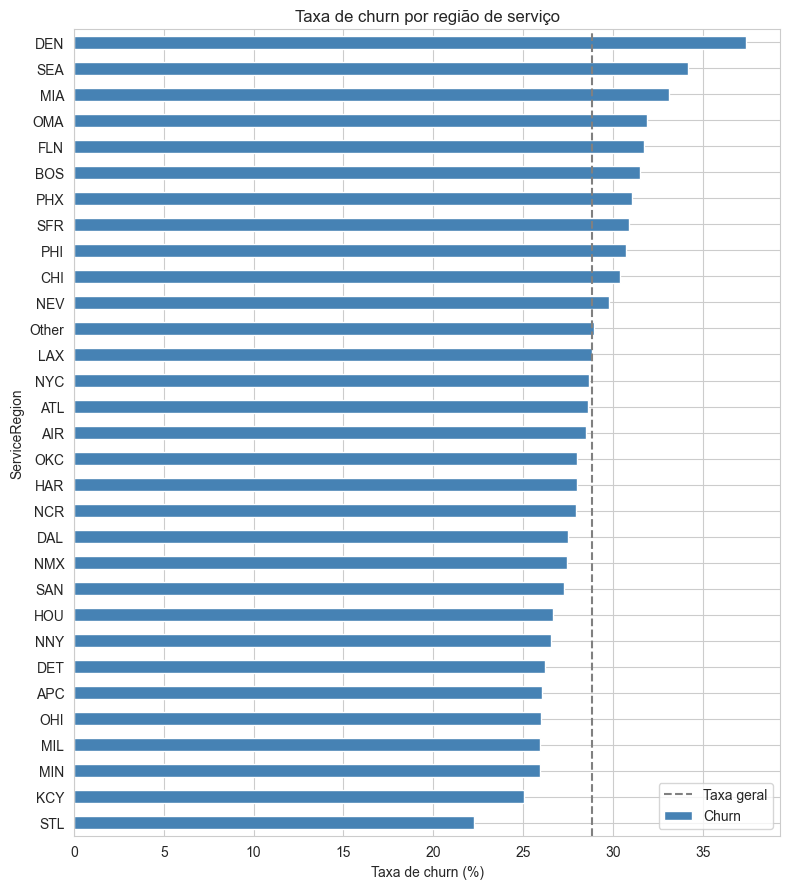

In [21]:
# Taxa de churn por região
taxa_regiao = df.groupby('ServiceRegion')['Churn'].mean().sort_values() * 100
taxa_regiao.plot(kind='barh', figsize=(8, 9), color='steelblue')
plt.axvline(df['Churn'].mean() * 100, color='gray', linestyle='--', label='Taxa geral')
plt.xlabel('Taxa de churn (%)')
plt.title('Taxa de churn por região de serviço')
plt.legend()
plt.tight_layout()
plt.show()

### 8. One-hot encoding: PrizmCode, Occupation, MaritalStatus e ServiceRegion

Estas variáveis são **nominais**: não existe ordem entre suas categorias (não faz sentido dizer
que "Rural" é maior que "Suburban", ou que "Student" é maior que "Retired"). Se as codificássemos
como números (1, 2, 3...), o modelo interpretaria uma ordem inexistente.

O one-hot encoding cria uma coluna binária para cada categoria. Por exemplo, `MaritalStatus` gera
`MaritalStatus_Yes`, `MaritalStatus_No` e `MaritalStatus_Unknown`, e cada cliente tem valor 1 em
apenas uma delas. Mantivemos a categoria `Unknown` como coluna própria, pois a ausência da
informação pode ser relevante para o modelo.

In [22]:
colunas_onehot = ['PrizmCode', 'Occupation', 'MaritalStatus', 'ServiceRegion']
print(f"Número de colunas antes do one-hot: {df.shape[1]}")

df = pd.get_dummies(df, columns=colunas_onehot, prefix=colunas_onehot, dtype=int)

print(f"Número de colunas depois do one-hot: {df.shape[1]}")

# Verificação: não pode restar nenhuma coluna de texto
restantes = df.select_dtypes(include=['object', 'string']).columns.tolist()
assert len(restantes) == 0, f"Ainda há colunas de texto: {restantes}"
print("✓ Todas as variáveis estão em formato numérico.")

Número de colunas antes do one-hot: 59
Número de colunas depois do one-hot: 101
✓ Todas as variáveis estão em formato numérico.


### 9. Variáveis derivadas: fase da fidelidade contratual

A análise da taxa de churn por mês de serviço revela um padrão muito marcado:

| Fase | Meses de serviço | Clientes | Taxa de churn |
|---|---|---|---|
| Em fidelidade | até 10 | 10.639 | **17,1%** |
| Fim da fidelidade | 11 e 12 | 6.336 | **42,7%** |
| Pós-fidelidade | 13 ou mais | 34.072 | 29,9% |

O churn é baixo nos primeiros 10 meses, quase **triplica** nos meses 11 e 12 e depois se estabiliza
próximo da média. O padrão é compatível com um **contrato de fidelidade de 12 meses**: enquanto a
multa rescisória está vigente, o cliente permanece mesmo insatisfeito; quando ela deixa de valer,
uma parcela relevante cancela. O dataset não contém informação sobre contratos, portanto essa é uma
hipótese de negócio, mas fortemente sustentada pelos dados (mais de 6 mil clientes na janela).

Embora `MonthsInService` já esteja no dataset, modelos lineares como a Regressão Logística só
capturam relações do tipo "quanto mais, maior (ou menor)" e não conseguem representar um pico
isolado. Por isso, criamos duas variáveis binárias:

- **`Contract_Locked`:** 1 se o cliente tem até 10 meses de serviço (período de fidelidade);
- **`Contract_EndWindow`:** 1 se o cliente está entre o 11º e o 12º mês (fim da fidelidade).

Clientes com 13 meses ou mais têm as duas variáveis iguais a 0.

**Implicação para o negócio:** as ações de retenção devem abordar o cliente **antes** do 11º mês,
ainda dentro do período de fidelidade.

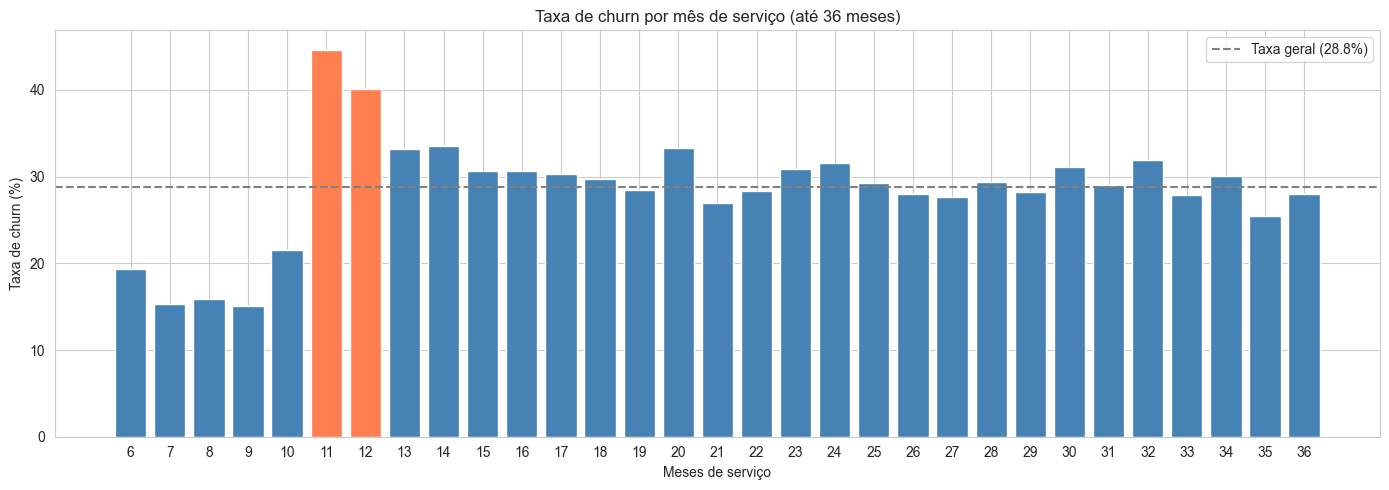

In [23]:
# Taxa de churn por mês de serviço (até 36 meses, onde os grupos são maiores)
churn_mes = df[df['MonthsInService'] <= 36].groupby('MonthsInService')['Churn'].agg(
    clientes='count', taxa_churn='mean')
churn_mes['taxa_churn'] = churn_mes['taxa_churn'] * 100

cores = ['coral' if m in (11, 12) else 'steelblue' for m in churn_mes.index]
plt.figure(figsize=(14, 5))
plt.bar(churn_mes.index, churn_mes['taxa_churn'], color=cores)
plt.axhline(df['Churn'].mean() * 100, color='gray', linestyle='--',
            label=f"Taxa geral ({df['Churn'].mean() * 100:.1f}%)")
plt.xlabel('Meses de serviço')
plt.ylabel('Taxa de churn (%)')
plt.title('Taxa de churn por mês de serviço (até 36 meses)')
plt.xticks(churn_mes.index)
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
# Fase da fidelidade contratual
df['Contract_Locked']    = (df['MonthsInService'] <= 10).astype(int)
df['Contract_EndWindow'] = df['MonthsInService'].between(11, 12).astype(int)

# Verificação: taxa de churn em cada fase
fase = np.select(
    [df['Contract_Locked'] == 1, df['Contract_EndWindow'] == 1],
    ['1. Em fidelidade (até 10 meses)', '2. Fim da fidelidade (11-12 meses)'],
    default='3. Pós-fidelidade (13+ meses)'
)
resumo_fase = df.groupby(fase)['Churn'].agg(clientes='count', taxa_churn='mean')
resumo_fase['taxa_churn'] = (resumo_fase['taxa_churn'] * 100).round(1)
resumo_fase

,clientes,taxa_churn
1. Em fidelidade (até 10 meses),10639,17.1
2. Fim da fidelidade (11-12 meses),6336,42.7
3. Pós-fidelidade (13+ meses),34072,29.9


In [25]:
df.head()

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,ServiceRegion_OMA,ServiceRegion_Other,ServiceRegion_PHI,ServiceRegion_PHX,ServiceRegion_SAN,ServiceRegion_SEA,ServiceRegion_SFR,ServiceRegion_STL,Contract_Locked,Contract_EndWindow
0,3000002,1,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,...,0,0,0,0,0,1,0,0,0,0
1,3000010,1,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,...,0,1,0,0,0,0,0,0,0,0
2,3000014,0,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,3000022,0,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,...,0,1,0,0,0,0,0,0,0,0
4,3000026,1,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,...,0,0,0,0,0,0,0,0,0,0


=== DISTRIBUIÇÃO DA VARIÁVEL TARGET ===

Contagem:
Churn
0    36336
1    14711
Name: count, dtype: int64

Percentual:
Sem churn (0): 71.18%
Com churn (1): 28.82%


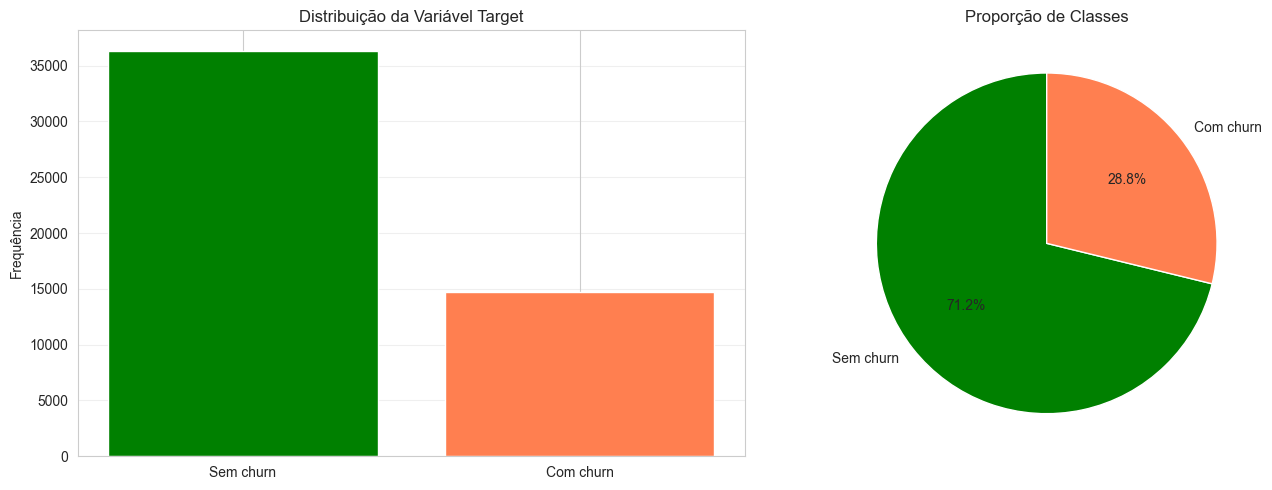


Ratio de balanceamento: 0.40
⚠️ Dataset desbalanceado! Considere usar técnicas como SMOTE ou class_weight.


In [26]:
print("=== DISTRIBUIÇÃO DA VARIÁVEL TARGET ===\n")
target_counts = df['Churn'].value_counts().sort_index()
target_percentages = df['Churn'].value_counts(normalize=True).sort_index() * 100

print("Contagem:")
print(target_counts)
print("\nPercentual:")
for idx, pct in target_percentages.items():
    label = "Sem churn" if idx == 0 else "Com churn"
    print(f"{label} ({idx}): {pct:.2f}%")

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de barras
axes[0].bar(['Sem churn', 'Com churn'], target_counts.values, color=['green', 'coral'])
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição da Variável Target')
axes[0].grid(axis='y', alpha=0.3)

# Gráfico de pizza
axes[1].pie(target_counts.values, labels=['Sem churn', 'Com churn'],
            autopct='%1.1f%%', colors=['green', 'coral'], startangle=90)
axes[1].set_title('Proporção de Classes')

plt.tight_layout()
plt.show()

# Verificar se há desbalanceamento
ratio = target_counts.min() / target_counts.max()
print(f"\nRatio de balanceamento: {ratio:.2f}")
if ratio < 0.5:
    print("⚠️ Dataset desbalanceado! Considere usar técnicas como SMOTE ou class_weight.")
else:
    print("✓ Dataset razoavelmente balanceado.")

In [27]:
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51047 entries, 0 to 51046
Columns: 103 entries, CustomerID to Contract_EndWindow
dtypes: float64(27), int64(76)
memory usage: 40.1 MB


# Tratamento de valores ausentes

O tratamento foi dividido em etapas:
1. Identificar os valores ausentes explícitos (`NaN`);
2. Identificar os valores ausentes disfarçados (como idade igual a 0);
3. Verificar se a ausência de informação tem relação com o churn;
4. Criar indicadores (flags) de ausência e converter os valores ausentes disfarçados em `NaN`;
5. Remover registros e colunas sem valor para o modelo.

=== ANÁLISE DE MISSING VALUES ===

                                      Coluna  Missing_Count  \
HandsetModels                  HandsetModels              1   
CurrentEquipmentDays    CurrentEquipmentDays              1   
Handsets                            Handsets              1   
MonthlyRevenue                MonthlyRevenue            156   
OverageMinutes                OverageMinutes            156   
MonthlyMinutes                MonthlyMinutes            156   
TotalRecurringCharge    TotalRecurringCharge            156   
DirectorAssistedCalls  DirectorAssistedCalls            156   
RoamingCalls                    RoamingCalls            156   
PercChangeMinutes          PercChangeMinutes            367   
PercChangeRevenues        PercChangeRevenues            367   
AgeHH1                                AgeHH1            909   
AgeHH2                                AgeHH2            909   
HandsetPrice                    HandsetPrice          28982   

                   

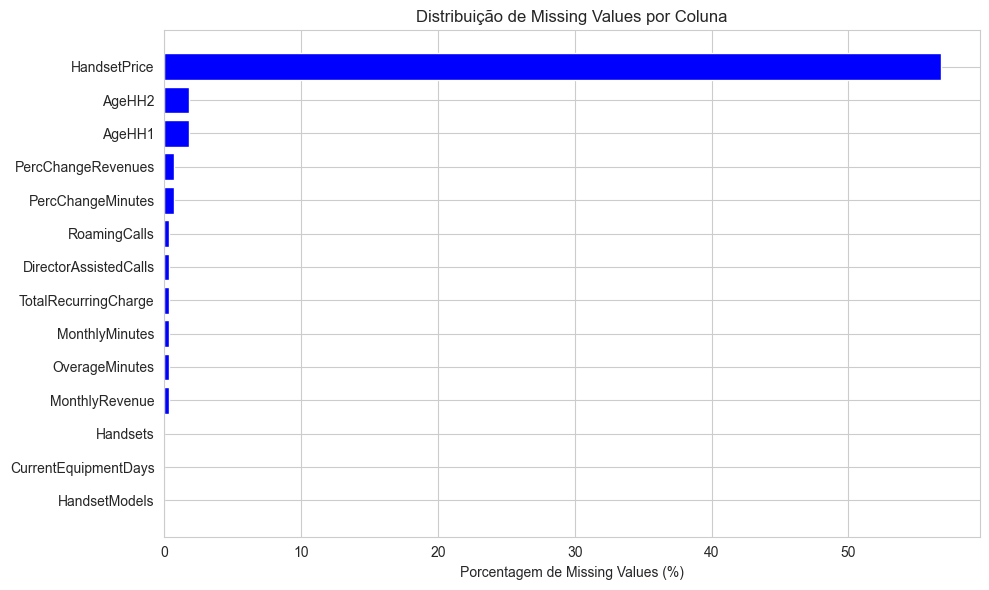

In [28]:
# Análise de valores ausentes
print("=== ANÁLISE DE MISSING VALUES ===\n")

missing_values = pd.DataFrame({
    'Coluna': df.columns,
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})

missing_values = missing_values[missing_values['Missing_Count'] > 0].sort_values(
    by='Missing_Percentage', ascending=True
)

if len(missing_values) > 0:
    print(missing_values)

    # Visualizar missing values
    plt.figure(figsize=(10, 6))
    plt.barh(missing_values['Coluna'], missing_values['Missing_Percentage'], color='blue')
    plt.xlabel('Porcentagem de Missing Values (%)')
    plt.title('Distribuição de Missing Values por Coluna')
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum missing value detectado!")

**Valores ausentes explícitos:**

- `HandsetPrice` tem **56,78%** de ausência: são os registros originalmente marcados como `"Unknown"`,
  convertidos para `NaN` na etapa de feature engineering.
- As 6 colunas de uso (`MonthlyRevenue`, `MonthlyMinutes`, `TotalRecurringCharge`,
  `DirectorAssistedCalls`, `OverageMinutes` e `RoamingCalls`) têm exatamente 156 ausentes cada.
- `PercChangeMinutes` e `PercChangeRevenues` têm 367 ausentes cada.
- `Handsets`, `HandsetModels` e `CurrentEquipmentDays` têm `NaN` em um único registro.

No entanto, essa análise considera apenas células vazias. Como identificado no dicionário de
variáveis, algumas colunas usam valores disfarçados para representar informação ausente
(ex.: idade igual a 0). Esses casos não aparecem como `NaN` e precisam ser contabilizados à parte.

=== ANÁLISE DE MISSING VALUES DISFARÇADOS ===

               Coluna  Missing_Count  Sentinel_Count  Total_Count  Total_Percentage
         HandsetPrice        28982.0             0.0      28982.0             56.78
               AgeHH1          909.0         26087.0      26996.0             52.88
               AgeHH2          909.0         13917.0      14826.0             29.04
          IncomeGroup            0.0         12835.0      12835.0             25.14
   PercChangeRevenues          367.0             0.0        367.0              0.72
    PercChangeMinutes          367.0             0.0        367.0              0.72
 TotalRecurringCharge          156.0             0.0        156.0              0.31
       MonthlyMinutes          156.0             0.0        156.0              0.31
       MonthlyRevenue          156.0             0.0        156.0              0.31
       OverageMinutes          156.0             0.0        156.0              0.31
         RoamingCalls        

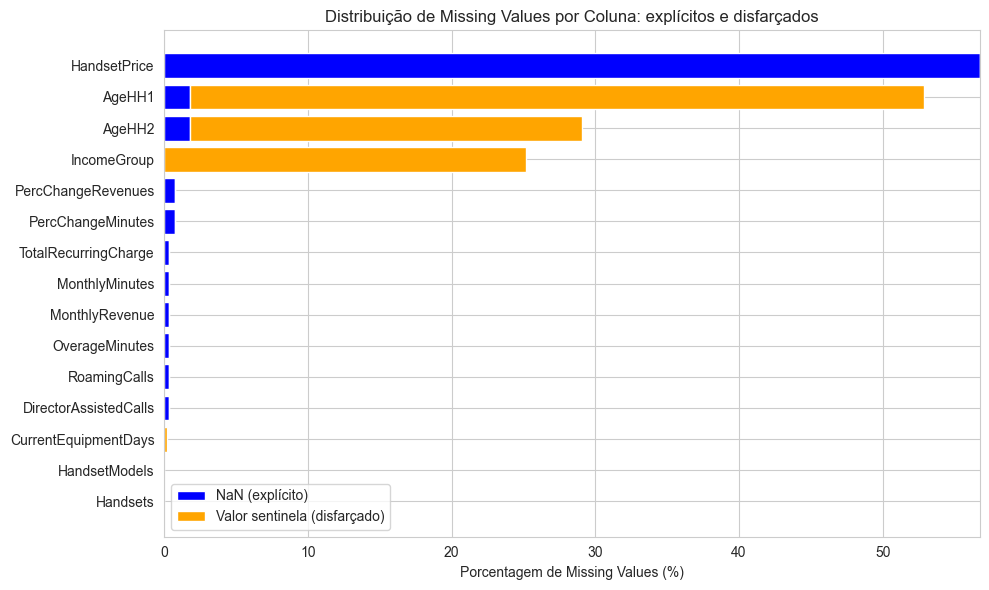

In [29]:
# Análise de valores ausentes disfarçados
print("=== ANÁLISE DE MISSING VALUES DISFARÇADOS ===\n")

# Valores sentinela identificados no dicionário de variáveis
sentinelas = pd.DataFrame({
    'Coluna': ['AgeHH1', 'AgeHH2', 'IncomeGroup', 'CurrentEquipmentDays'],
    'Sentinel_Count': [
        (df['AgeHH2'] == 0).sum(),                          # idade 0 = não informada
         ((df['AgeHH1'] == 0) & (df['AgeHH2'] == 0)).sum(),  # só é ausente quando AgeHH1 também é 0
        (df['IncomeGroup'] == 0).sum(),                     # renda 0 = não informada
        (df['CurrentEquipmentDays'] < 0).sum(),             # dias negativos = erro de registro
    ],
})

# Junta os ausentes explícitos (NaN) com os disfarçados (sentinela)
missing_total = pd.merge(
    missing_values[['Coluna', 'Missing_Count']], sentinelas, on='Coluna', how='outer'
).fillna(0)
missing_total['Total_Count'] = missing_total['Missing_Count'] + missing_total['Sentinel_Count']
missing_total['Total_Percentage'] = (missing_total['Total_Count'] / len(df) * 100).round(2)
missing_total = missing_total.sort_values(by='Total_Percentage', ascending=True)

print(missing_total.iloc[::-1].to_string(index=False))

# Visualizar: NaN (azul) + sentinela (laranja) empilhados
plt.figure(figsize=(10, 6))
plt.barh(missing_total['Coluna'], missing_total['Missing_Count'] / len(df) * 100,
         color='blue', label='NaN (explícito)')
plt.barh(missing_total['Coluna'], missing_total['Sentinel_Count'] / len(df) * 100,
         left=missing_total['Missing_Count'] / len(df) * 100,
         color='orange', label='Valor sentinela (disfarçado)')
plt.xlabel('Porcentagem de Missing Values (%)')
plt.title('Distribuição de Missing Values por Coluna: explícitos e disfarçados')
plt.legend()
plt.tight_layout()
plt.show()

**Resultado:** ao incluir os valores disfarçados, o cenário de dados ausentes muda:

| Coluna | Ausentes (só NaN) | Ausentes (NaN + sentinela) |
|---|---|---|
| `AgeHH1` | 1,78% | **29,04%** |
| `AgeHH2` | 1,78% | **29,04%** |
| `IncomeGroup` | 0% | **25,14%** |
| `CurrentEquipmentDays` | 0,00% | 0,15% |

`IncomeGroup` não tinha nenhum `NaN`, mas um quarto da base tem renda não informada.
Se esses valores fossem mantidos como 0, o modelo interpretaria esses clientes como a faixa de
renda mais baixa, uma informação incorreta.

**Atenção ao `AgeHH2`:** o valor 0 tem dois significados nessa coluna. Quando `AgeHH1` também é 0
(13.917 clientes), não há nenhum dado demográfico, e o 0 indica ausência. Quando `AgeHH1` tem uma
idade válida, o `AgeHH2 = 0` indica um domicílio com um único responsável (12.170 clientes), um
**zero legítimo**, que não deve ser tratado como ausente.

Além disso, a ausência de dados demográficos tem uma causa comum: entre os clientes sem idade
informada, 81% também não têm renda informada e 89% têm estado civil `Unknown`.

In [30]:
# Taxa de churn dos clientes com cada tipo de informação ausente
grupos = {
    'Sem dados de uso': df['MonthlyRevenue'].isna(),
    'Sem variação (PercChange)': df['PercChangeMinutes'].isna(),
    'Idade desconhecida (AgeHH1)': df['AgeHH1'].isna() | (df['AgeHH1'] == 0),
    'Renda desconhecida (IncomeGroup)': df['IncomeGroup'] == 0,
    'Preço do aparelho desconhecido': df['HandsetPrice_Unknown'] == 1,
}
taxa_ausentes = pd.DataFrame({
    'clientes': [m.sum() for m in grupos.values()],
    'taxa_churn (%)': [df.loc[m, 'Churn'].mean() * 100 for m in grupos.values()],
}, index=grupos.keys()).round(1)

print(taxa_ausentes)
print(f"\nTaxa geral de churn: {df['Churn'].mean() * 100:.1f}%")

                                  clientes  taxa_churn (%)
Sem dados de uso                       156            44.9
Sem variação (PercChange)              367            56.7
Idade desconhecida (AgeHH1)          14826            30.0
Renda desconhecida (IncomeGroup)     12835            30.2
Preço do aparelho desconhecido       28982            30.2

Taxa geral de churn: 28.8%


**A ausência de informação é, ela própria, um sinal de risco:**

| Grupo | Clientes | Taxa de churn |
|---|---|---|
| Sem dados de uso | 156 | 44,9% |
| Sem variação de uso (PercChange) | 367 | **56,7%** |
| Idade, renda ou preço do aparelho desconhecidos | 13–29 mil | ~30% |

A taxa geral é de 28,8%. Clientes sem registro de variação de uso cancelam com o **dobro** da
frequência média. Uma hipótese é que sejam clientes com pouco histórico na operadora, ou que já
haviam reduzido o uso antes de cancelar.

Se apenas preenchêssemos esses valores com a mediana, essa informação se perderia, pois o cliente
passaria a parecer "típico". Por isso, antes da imputação, criamos colunas indicadoras (flags) que
registram onde a informação estava ausente.

In [31]:
# Flags de ausência: 1 = informação ausente, 0 = informação disponível
df['Usage_Missing']        = df['MonthlyRevenue'].isna().astype(int)
df['PercChange_Missing']   = df['PercChangeMinutes'].isna().astype(int)
df['Demographics_Missing'] = (df['AgeHH1'].isna() | (df['AgeHH1'] == 0)).astype(int)
# HandsetPrice_Unknown já foi criada na etapa de feature engineering

print(df[['Usage_Missing', 'PercChange_Missing', 'Demographics_Missing']].sum())

Usage_Missing             156
PercChange_Missing        367
Demographics_Missing    14826
dtype: int64


### Conversão dos valores disfarçados em NaN

- **AgeHH1 = 0:** nenhuma idade válida de responsável pelo domicílio é zero (o menor valor diferente
  de zero na base é 18 anos). O 0 representa informação ausente e é convertido em `NaN`.
- **AgeHH2 = 0:** convertido em `NaN` **somente quando `AgeHH1` também é 0** (cadastro demográfico
  ausente). Quando `AgeHH1` tem idade válida, o zero indica domicílio com um único responsável e é
  mantido.
- **IncomeGroup = 0:** a renda é uma escala de 1 a 9; o 0 indica renda não informada e é convertido
  em `NaN`. Mantê-lo como número levaria o modelo a interpretar esses clientes como a faixa de renda
  mais baixa.
- **CurrentEquipmentDays < 0:** os 76 valores negativos estão todos entre -5 e -1, o que indica um
  pequeno erro no cálculo de datas (aparelho registrado poucos dias à frente). Como a magnitude é
  irrelevante, os valores foram **truncados em 0**.
- **MonthlyRevenue < 0:** os 3 valores negativos foram **mantidos**, pois são plausíveis
  (estornos ou créditos na fatura).

Foi criada uma **única flag** (`Demographics_Missing`) para a ausência de dados demográficos, pois
idade, renda e estado civil ausentes têm a mesma causa: o cliente não possui cadastro demográfico.

In [32]:
# AgeHH2 só vira NaN junto com AgeHH1 (cadastro demográfico ausente)
df.loc[df['AgeHH1'] == 0, ['AgeHH1', 'AgeHH2']] = np.nan

# Renda 0 = não informada
df.loc[df['IncomeGroup'] == 0, 'IncomeGroup'] = np.nan

# Dias negativos (-5 a -1) = erro de data, truncados em 0
df['CurrentEquipmentDays'] = df['CurrentEquipmentDays'].clip(lower=0)

print(df[['AgeHH1', 'AgeHH2', 'IncomeGroup']].isna().sum())
print(f"\nAgeHH2 = 0 mantidos (domicílio com um responsável): {(df['AgeHH2'] == 0).sum()}")

AgeHH1         14826
AgeHH2         14826
IncomeGroup    12835
dtype: int64

AgeHH2 = 0 mantidos (domicílio com um responsável): 12170


### Remoção de registros e colunas

**Registros removidos (2):**
- **Cliente sem informação de aparelhos:** um único registro não tem `Handsets`, `HandsetModels`
  nem `CurrentEquipmentDays`.
- **Cliente com `UniqueSubs = 196`:** o segundo maior valor da base é 18. O registro tem 53
  assinaturas ativas com receita mensal de apenas 67,74, uma combinação incoerente que indica
  erro de carga.

**Colunas removidas (4):**
- **`CustomerID`:** é apenas um identificador; não tem relação com o comportamento do cliente.
- **`RetentionCalls`, `RetentionOffersAccepted` e `MadeCallToRetentionTeam`:** risco de vazamento
  de informação (*target leakage*). O contato com a equipe de retenção geralmente acontece quando o
  cliente já decidiu cancelar, e esse registro pode não existir no momento em que o modelo precisa
  fazer a previsão. Perder esse sinal preditivo é preferível a publicar um modelo que só funciona
  porque "enxerga" o cancelamento antes da hora.

In [33]:
print(f"Linhas antes: {len(df)}")

df = df.dropna(subset=['Handsets'])              # 1 cliente sem dados de aparelho
df = df[df['UniqueSubs'] < 100]                  # 1 cliente com 196 assinaturas (erro de carga)
df = df.reset_index(drop=True)

print(f"Linhas depois: {len(df)}")

colunas_remover = ['CustomerID',                 # identificador
                   'RetentionCalls',             # vazamento de informação
                   'RetentionOffersAccepted',    # vazamento de informação
                   'MadeCallToRetentionTeam']    # vazamento de informação
df = df.drop(columns=colunas_remover)

Linhas antes: 51047
Linhas depois: 51045


=== MISSING VALUES APÓS O TRATAMENTO ===

               Coluna  Missing_Count  Missing_Percentage
       MonthlyRevenue            156                0.31
       MonthlyMinutes            156                0.31
 TotalRecurringCharge            156                0.31
DirectorAssistedCalls            156                0.31
       OverageMinutes            156                0.31
         RoamingCalls            156                0.31
    PercChangeMinutes            367                0.72
   PercChangeRevenues            367                0.72
          IncomeGroup          12833               25.14
               AgeHH1          14824               29.04
               AgeHH2          14824               29.04
         HandsetPrice          28980               56.77


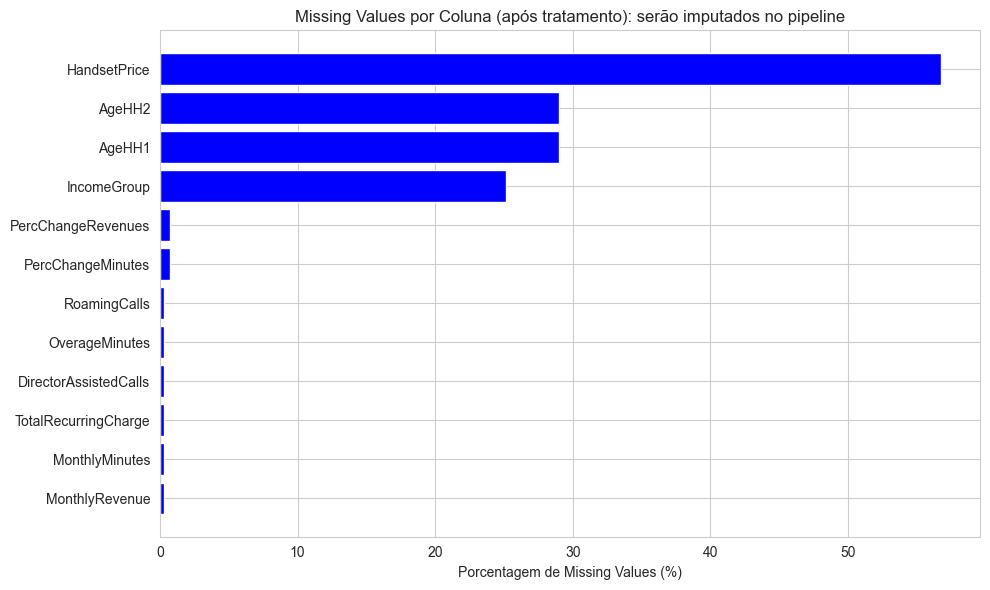


Dimensão final: (51045, 102)


In [34]:
# Situação final: mesma análise do início, após o tratamento
print("=== MISSING VALUES APÓS O TRATAMENTO ===\n")

missing_final = pd.DataFrame({
    'Coluna': df.columns,
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})
missing_final = missing_final[missing_final['Missing_Count'] > 0].sort_values(
    by='Missing_Percentage', ascending=True
)
print(missing_final.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.barh(missing_final['Coluna'], missing_final['Missing_Percentage'], color='blue')
plt.xlabel('Porcentagem de Missing Values (%)')
plt.title('Missing Values por Coluna (após tratamento): serão imputados no pipeline')
plt.tight_layout()
plt.show()

print(f"\nDimensão final: {df.shape}")

## Conclusão do tratamento de valores ausentes

Nesta etapa, os valores ausentes foram **preparados**, mas ainda não preenchidos:

| Ação | Tipo de tratamento | Efeito na análise de missing values |
|---|---|---|
| Converter zeros e negativos em NaN | Padronização dos ausentes | % aumenta: o missing disfarçado fica visível |
| Criar flags (Usage_Missing etc.) | Preservação da informação | Nenhum efeito: são colunas novas, sem valores ausentes |
| Remover a linha sem Handsets | Remoção de registro | `Handsets` e `HandsetModels` deixam de ter ausentes |
| Remoção do `CustomerID` | Limpeza | Nenhum efeito |

Por isso, a análise final ainda apresenta valores ausentes: ela agora mostra o volume **real** de
informação faltante. Esses valores serão preenchidos com a **mediana** de cada coluna **dentro do
pipeline de cada modelo**, calculada apenas com os dados de treino, para evitar vazamento de
informação (*data leakage*).

# Análise das variáveis numéricas

As análises de outliers, distribuição e correlação entre features são aplicadas apenas às
**variáveis não binárias**. Em uma variável 0/1 não existem valores extremos, e medidas como
assimetria apenas refletem a proporção de valores 1. Por exemplo, o critério Z-score classificaria
como "outliers" os 4.153 clientes que possuem trailer (`RVOwner = 1`), simplesmente por serem
minoria. As variáveis binárias são incluídas apenas na análise de correlação com o Churn.

In [35]:
# Separa as features numéricas em binárias (0/1) e não binárias
colunas_numericas = df.select_dtypes(include=[np.number]).columns.drop('Churn')
colunas_binarias_todas = [c for c in colunas_numericas if df[c].dropna().nunique() <= 2]
colunas_continuas = [c for c in colunas_numericas if c not in colunas_binarias_todas]

print(f"Total de features numéricas: {len(colunas_numericas)}")
print(f"  Binárias (0/1):     {len(colunas_binarias_todas)}")
print(f"  Não binárias:       {len(colunas_continuas)}")
print(f"\nVariáveis não binárias analisadas:\n{colunas_continuas}")

Total de features numéricas: 101
  Binárias (0/1):     67
  Não binárias:       34

Variáveis não binárias analisadas:
['MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'AdjustmentsToCreditRating', 'HandsetPrice', 'CreditRating']


## Análise de outliers

**Objetivo:** identificar valores extremos e decidir se representam erros de registro ou
comportamentos reais de clientes.

**Método:** critério do **intervalo interquartil (IQR)**. Um valor é considerado outlier quando está
abaixo de Q1 − 1,5 × IQR ou acima de Q3 + 1,5 × IQR. O IQR foi preferido ao Z-score porque o Z-score
pressupõe uma distribuição aproximadamente normal, o que não ocorre na maior parte das variáveis
desta base (ver análise de distribuições).

In [36]:
# Outliers pelo critério IQR, apenas nas variáveis não binárias
resumo_outliers = []
for col in colunas_continuas:
    serie = df[col].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((serie < lim_inf) | (serie > lim_sup)).sum()
    resumo_outliers.append({
        'Coluna': col,
        'Outliers (IQR)': n_out,
        '% da base': round(n_out / len(serie) * 100, 2),
        'Mediana': round(serie.median(), 2),
        'Limite superior': round(lim_sup, 2),
        'Máximo': round(serie.max(), 2),
    })

resumo_outliers = pd.DataFrame(resumo_outliers).sort_values('% da base', ascending=False)
print(resumo_outliers.to_string(index=False))

                   Coluna  Outliers (IQR)  % da base  Mediana  Limite superior  Máximo
       PercChangeRevenues           13221      26.09    -0.30            14.65 2483.50
             RoamingCalls            8835      17.36     0.00             0.75 1112.40
         CallWaitingCalls            7448      14.59     0.30             3.25  212.70
        PercChangeMinutes            6807      13.43    -5.00           289.50 5192.00
        CustomerCareCalls            6721      13.17     0.00             4.25  327.30
           OverageMinutes            5842      11.48     3.00           102.50 4321.00
    DirectorAssistedCalls            5530      10.87     0.25             2.47  159.39
             BlockedCalls            5517      10.81     1.00             9.25  384.30
             InboundCalls            4973       9.74     2.00            23.25  519.30
            ThreewayCalls            4622       9.05     0.00             0.75   66.00
                 Handsets            4414  

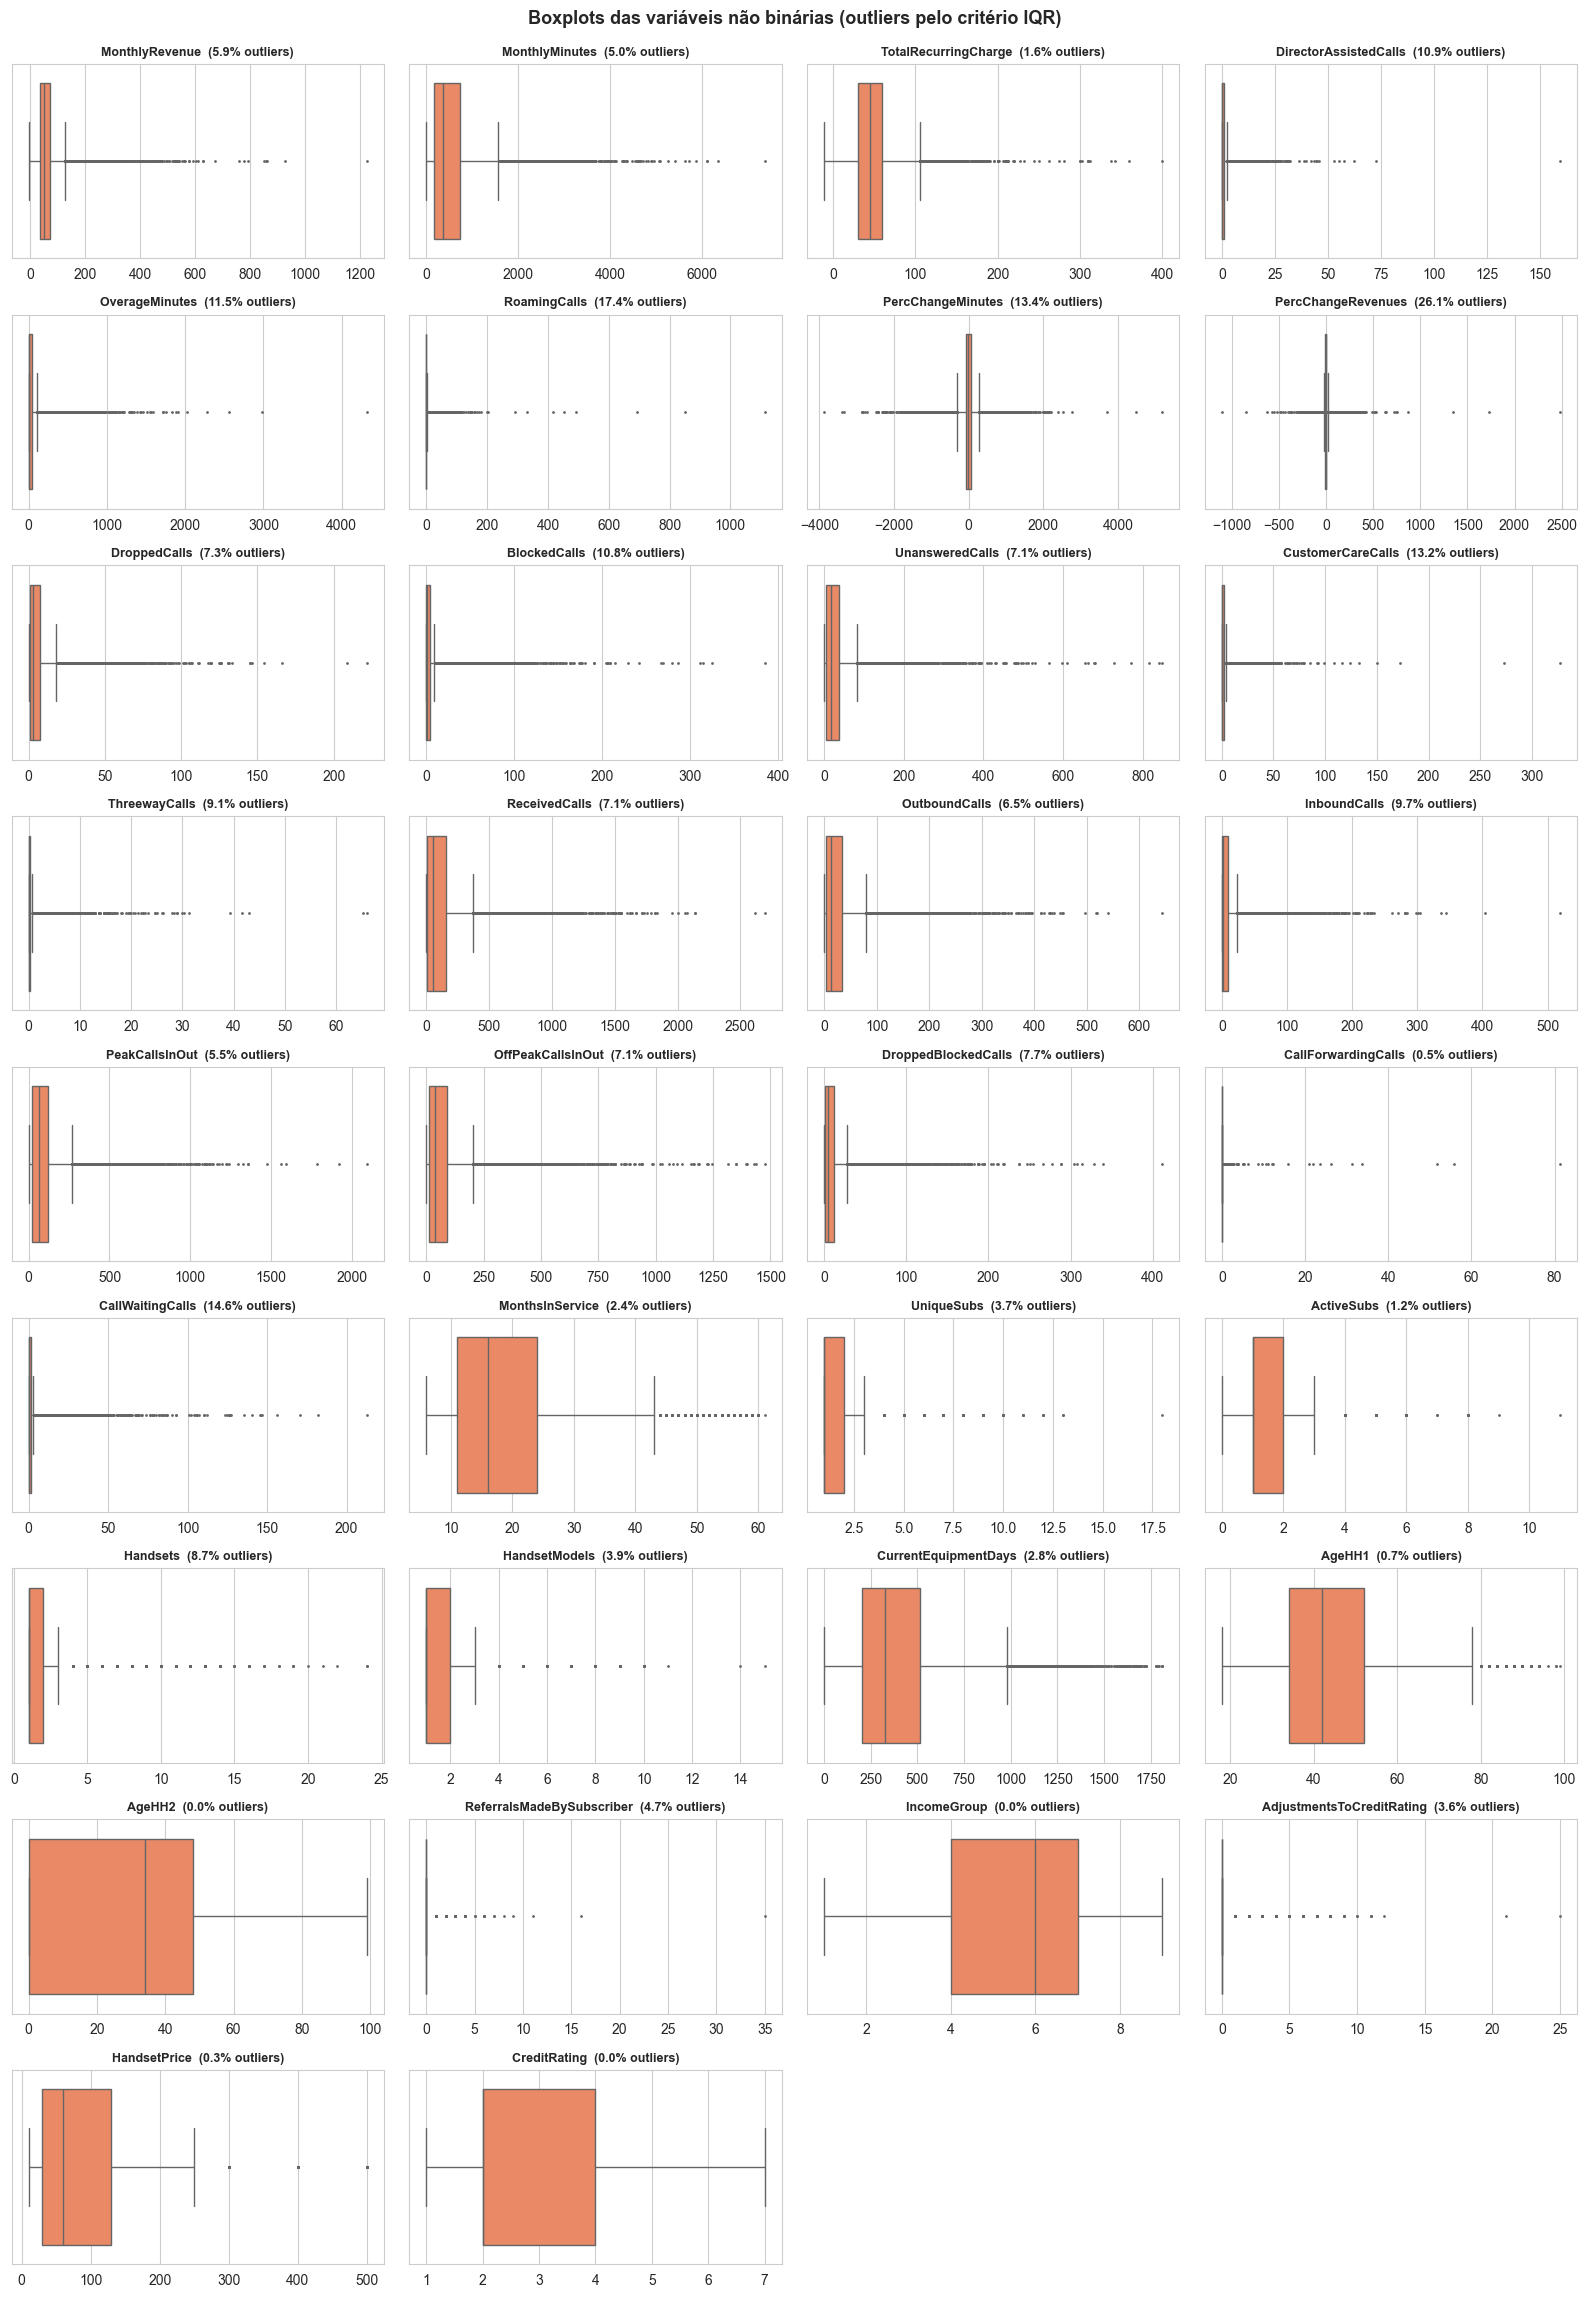

In [37]:
ncols = 4
nrows = int(np.ceil(len(colunas_continuas) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 2.6 * nrows))
axes = axes.ravel()

for idx, col in enumerate(colunas_continuas):
    sns.boxplot(x=df[col], ax=axes[idx], color='coral', fliersize=1)
    pct = resumo_outliers.set_index('Coluna').loc[col, '% da base']
    axes[idx].set_title(f'{col}  ({pct:.1f}% outliers)', fontsize=9, fontweight='bold')
    axes[idx].set_xlabel('')

for ax in axes[len(colunas_continuas):]:
    fig.delaxes(ax)

plt.suptitle('Boxplots das variáveis não binárias (outliers pelo critério IQR)',
             fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

In [38]:
# Os clientes com valores extremos têm comportamento de churn diferente?
linhas = []
for col in ['MonthlyRevenue', 'MonthlyMinutes', 'OverageMinutes', 'CustomerCareCalls',
            'CurrentEquipmentDays', 'MonthsInService']:
    serie = df[col]
    q1, q3 = serie.quantile([0.25, 0.75])
    outlier = serie > q3 + 1.5 * (q3 - q1)
    linhas.append({
        'Coluna': col,
        'Clientes outliers': outlier.sum(),
        'Churn outliers (%)': round(df.loc[outlier, 'Churn'].mean() * 100, 1),
        'Churn demais (%)': round(df.loc[~outlier & serie.notna(), 'Churn'].mean() * 100, 1),
    })

print(pd.DataFrame(linhas).to_string(index=False))

              Coluna  Clientes outliers  Churn outliers (%)  Churn demais (%)
      MonthlyRevenue               2997                29.5              28.7
      MonthlyMinutes               2567                23.5              29.1
      OverageMinutes               5842                31.5              28.4
   CustomerCareCalls               6721                25.2              29.4
CurrentEquipmentDays               1446                39.2              28.5
     MonthsInService               1218                26.4              28.9


**Conclusões da análise de outliers:**

- **Muitas variáveis têm mais de 10% de outliers** (ex.: `PercChangeRevenues` 26,1%, `RoamingCalls`
  17,4%, `CallWaitingCalls` 14,6%). Isso não indica erro: a maioria dos clientes tem valores baixos
  ou iguais a zero, e uma minoria de usuários intensos forma uma cauda longa à direita.
- **Os valores máximos são plausíveis.** `MonthlyMinutes` chega a 7.359 minutos (cerca de 4 horas
  por dia) e `MonthlyRevenue` a 1.223, valores compatíveis com usuários intensos ou contas
  empresariais.
- **Os outliers carregam informação.** Clientes com aparelho muito antigo (`CurrentEquipmentDays`
  acima do limite) cancelam em 39,2% dos casos, contra 28,5% dos demais. Removê-los descartaria
  justamente um grupo de alto risco.

**Decisão:** os outliers são **mantidos**. O único valor identificado como erro de registro
(`UniqueSubs = 196`) já foi removido na etapa anterior. Modelos baseados em árvores não são
sensíveis a valores extremos; para a Regressão Logística e a MLP, as variáveis serão padronizadas
no pipeline de pré-processamento, e uma transformação logarítmica pode ser avaliada para as
variáveis de cauda mais longa.

## Análise de distribuições

**Objetivo:** entender o formato das variáveis não binárias e identificar assimetrias.

- **Assimetria (skewness):** próxima de 0 indica distribuição simétrica; acima de 1 (em módulo),
  fortemente assimétrica;
- **Curtose:** valores altos indicam caudas pesadas, com muitos valores extremos;
- **% de zeros:** mostra variáveis concentradas em zero.

In [39]:
dist = pd.DataFrame({
    'Assimetria (skew)': df[colunas_continuas].skew().round(2),
    'Curtose': df[colunas_continuas].kurtosis().round(2),
    '% de zeros': ((df[colunas_continuas] == 0).mean() * 100).round(1),
})
dist['Interpretação'] = pd.cut(
    dist['Assimetria (skew)'].abs(), bins=[-0.01, 0.5, 1, np.inf],
    labels=['Aproximadamente simétrica', 'Moderadamente assimétrica', 'Fortemente assimétrica']
)
dist = dist.sort_values('Assimetria (skew)', ascending=False)

print(dist.to_string())
print(f"\n{dist['Interpretação'].value_counts().to_string()}")

                           Assimetria (skew)   Curtose  % de zeros              Interpretação
CallForwardingCalls                    91.63  10063.47        99.5     Fortemente assimétrica
RoamingCalls                           57.88   5149.87        68.5     Fortemente assimétrica
ReferralsMadeBySubscriber              36.74   3495.17        95.3     Fortemente assimétrica
AdjustmentsToCreditRating              18.62    704.34        96.4     Fortemente assimétrica
ThreewayCalls                          17.55    604.17        72.7     Fortemente assimétrica
CustomerCareCalls                      14.24    577.64        54.9     Fortemente assimétrica
DirectorAssistedCalls                  13.57    599.24        48.0     Fortemente assimétrica
CallWaitingCalls                       11.12    218.80        49.0     Fortemente assimétrica
BlockedCalls                            9.79    168.29        27.3     Fortemente assimétrica
OverageMinutes                          8.11    158.01      

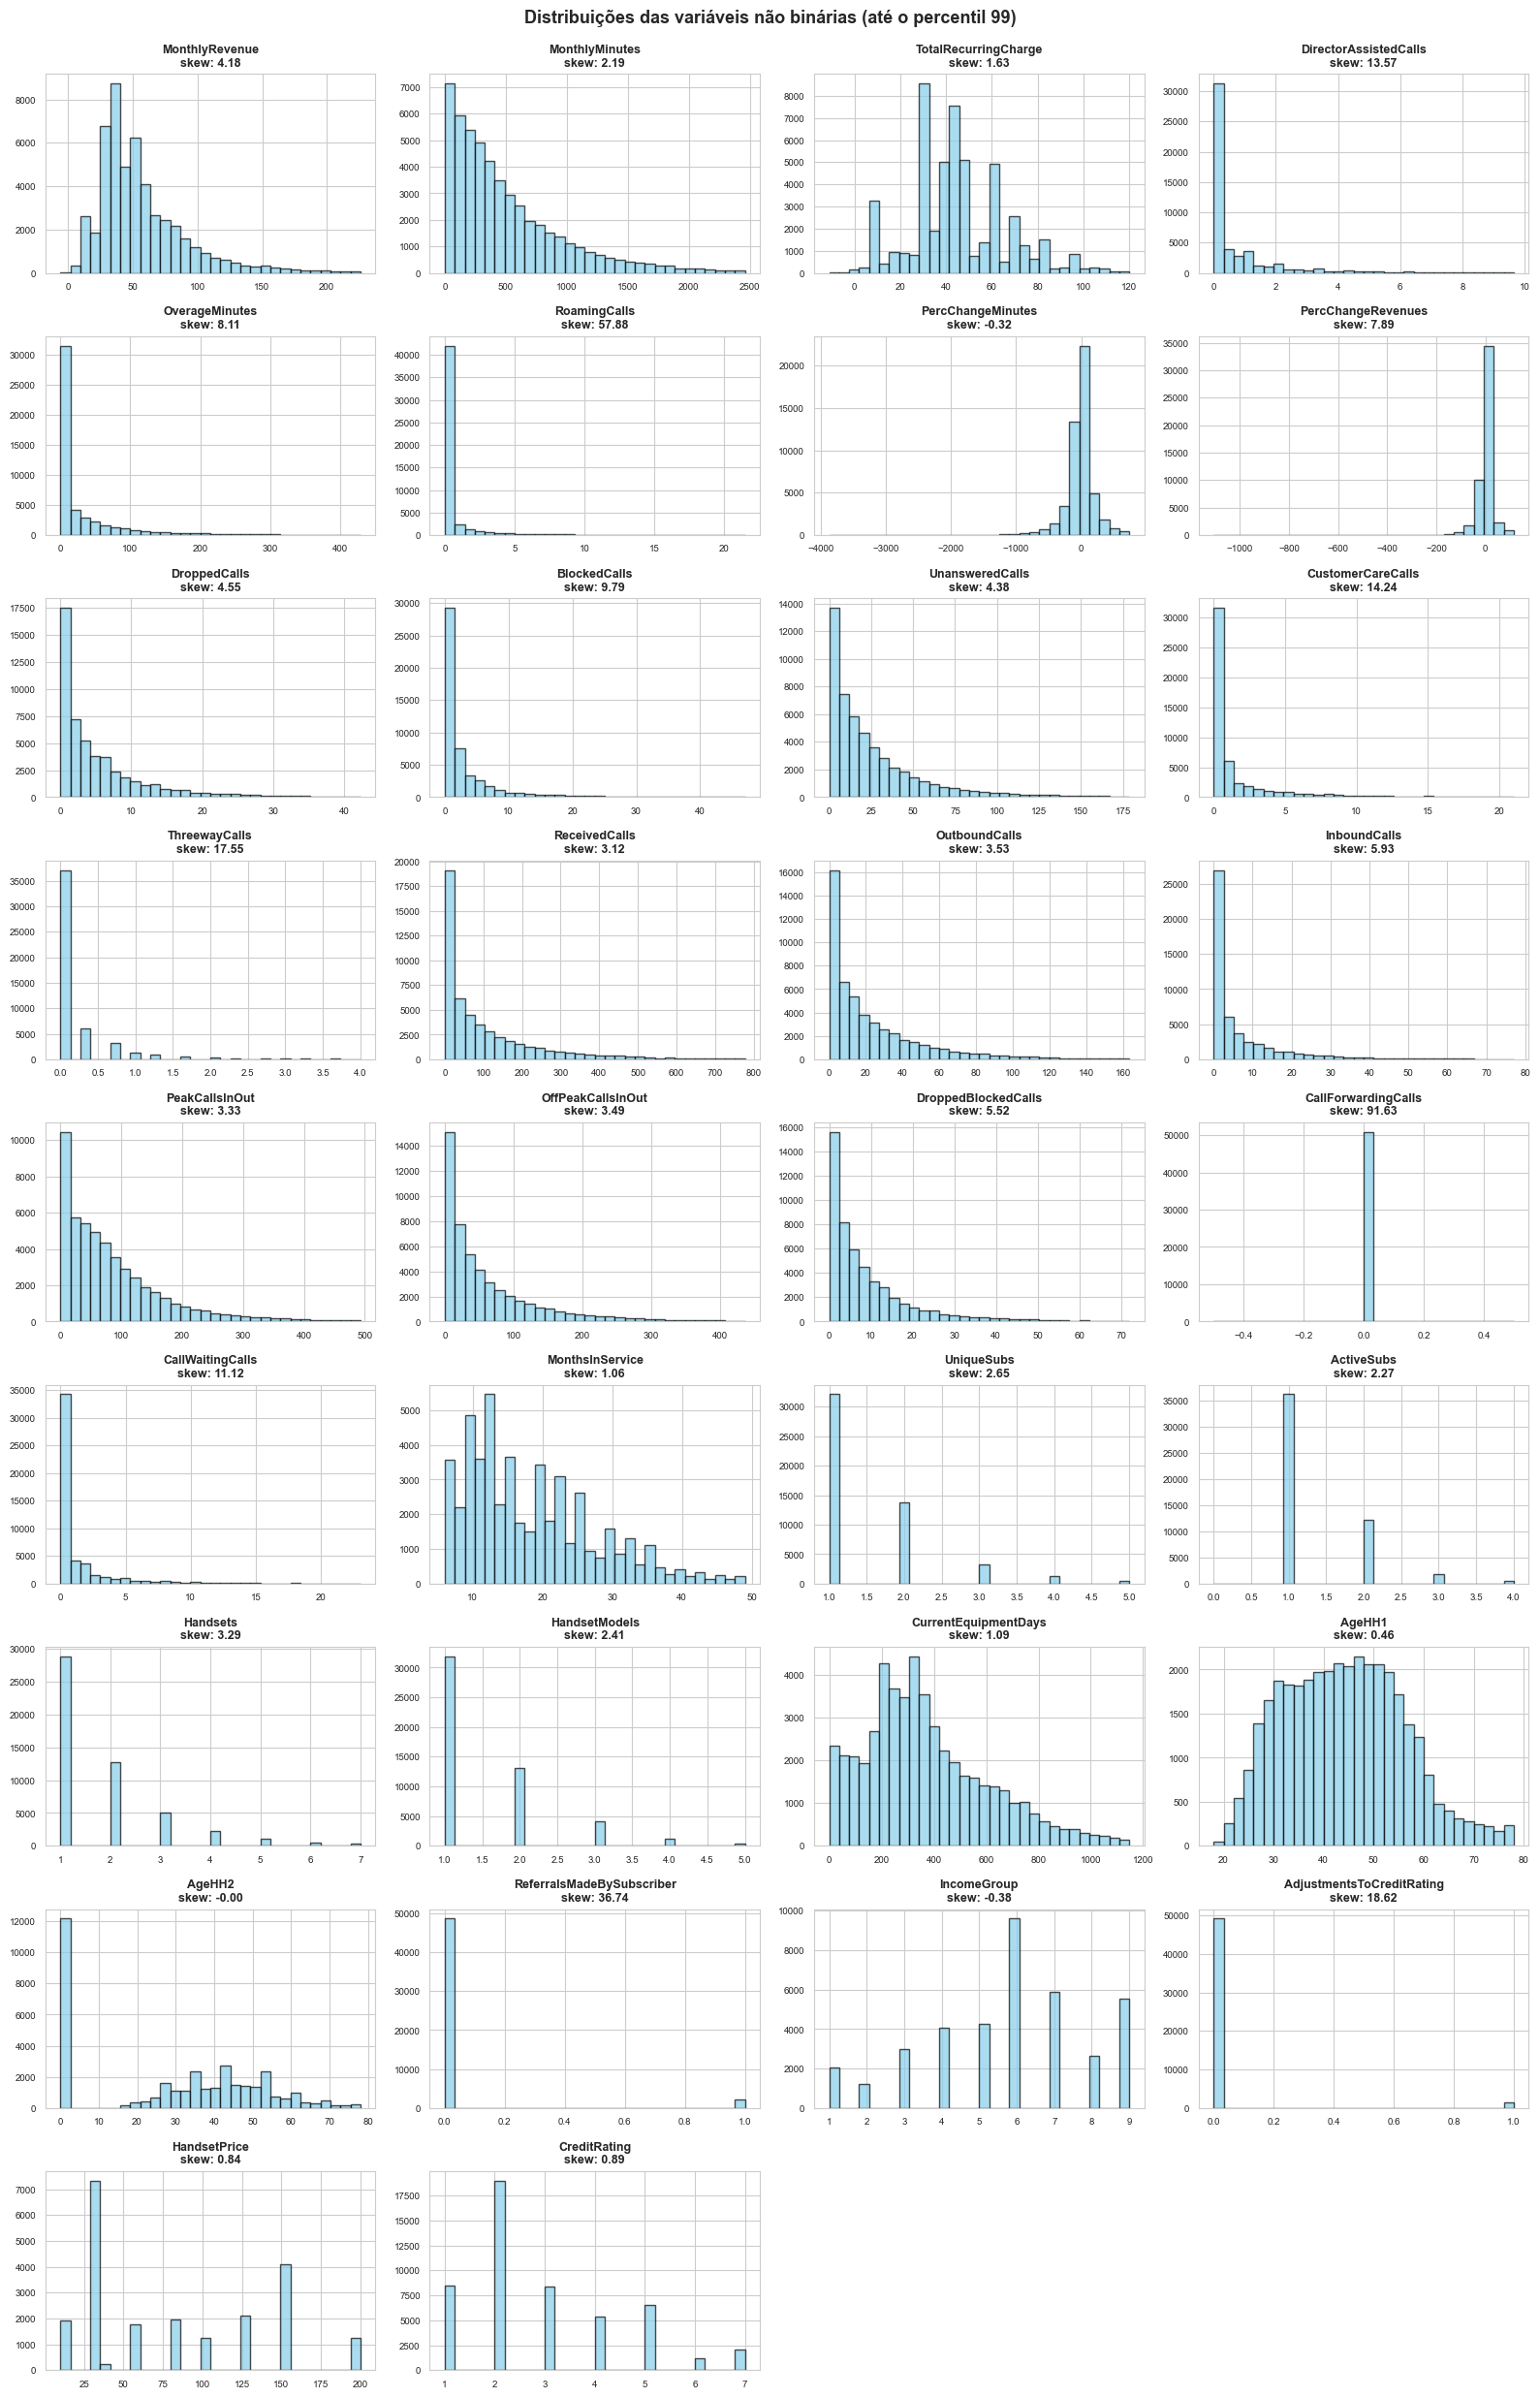

In [40]:
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 2.8 * nrows))
axes = axes.ravel()

for idx, col in enumerate(colunas_continuas):
    serie = df[col].dropna()
    limite = serie.quantile(0.99)   # corta o 1% mais extremo só para visualizar melhor
    axes[idx].hist(serie[serie <= limite], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
    axes[idx].set_title(f'{col}\nskew: {serie.skew():.2f}', fontsize=9, fontweight='bold')
    axes[idx].tick_params(labelsize=7)

for ax in axes[len(colunas_continuas):]:
    fig.delaxes(ax)

plt.suptitle('Distribuições das variáveis não binárias (até o percentil 99)',
             fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

**Conclusões da análise de distribuições:**

- **28 das 34 variáveis são fortemente assimétricas à direita**, típico de dados de uso: a maioria
  dos clientes usa pouco e poucos usam muito.
- **Algumas variáveis são quase constantes:** `CallForwardingCalls` (99,5% de zeros),
  `AdjustmentsToCreditRating` (96,4%) e `ReferralsMadeBySubscriber` (95,3%) trazem pouca informação
  para o modelo.
- **Apenas `AgeHH1`, `IncomeGroup` e `PercChangeMinutes` são aproximadamente simétricas.** `AgeHH2`
  também tem assimetria próxima de zero, mas por outro motivo: a distribuição tem dois grupos, os
  23,8% de zeros legítimos (domicílios com um responsável) e as idades válidas. Isso mostra que
  assimetria próxima de zero não significa distribuição normal.

**Consequências:**
- A forte assimetria **justifica a imputação pela mediana** em vez da média, que seria puxada pelos
  valores extremos;
- Também justifica o uso do critério IQR, e não do Z-score, na análise de outliers.

## Análise de correlações

**Objetivo:** identificar quais variáveis têm relação com o churn e detectar variáveis redundantes
entre si (multicolinearidade).

- **Correlação com o Churn:** inclui todas as features, inclusive as binárias. A correlação de
  Pearson entre uma variável 0/1 e o Churn (correlação ponto-bisserial) é uma medida válida.
- **Correlação entre features:** inclui apenas as variáveis não binárias. As colunas geradas pelo
  one-hot encoding são negativamente correlacionadas entre si por construção, o que poluiria a análise.

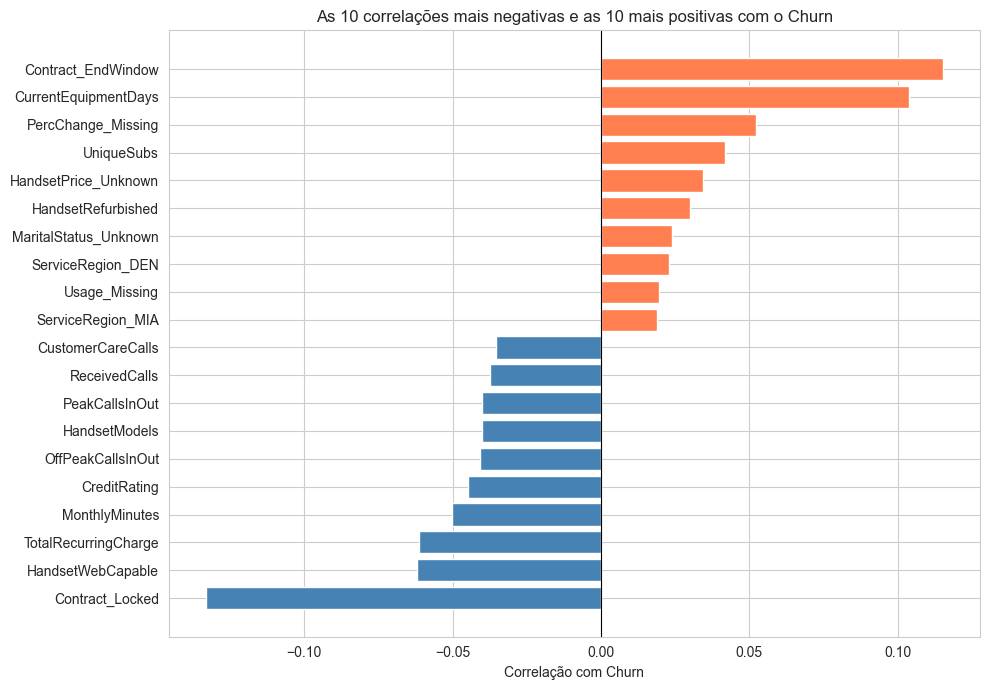

Maior correlação absoluta com o Churn: 0.133


In [41]:
# Correlação de todas as features com o Churn
corr_target = df[list(colunas_numericas)].corrwith(df['Churn']).sort_values()

top = pd.concat([corr_target.head(10), corr_target.tail(10)])
cores = ['steelblue' if v < 0 else 'coral' for v in top]

plt.figure(figsize=(10, 7))
plt.barh(top.index, top.values, color=cores)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Correlação com Churn')
plt.title('As 10 correlações mais negativas e as 10 mais positivas com o Churn')
plt.tight_layout()
plt.show()

print(f"Maior correlação absoluta com o Churn: {corr_target.abs().max():.3f}")

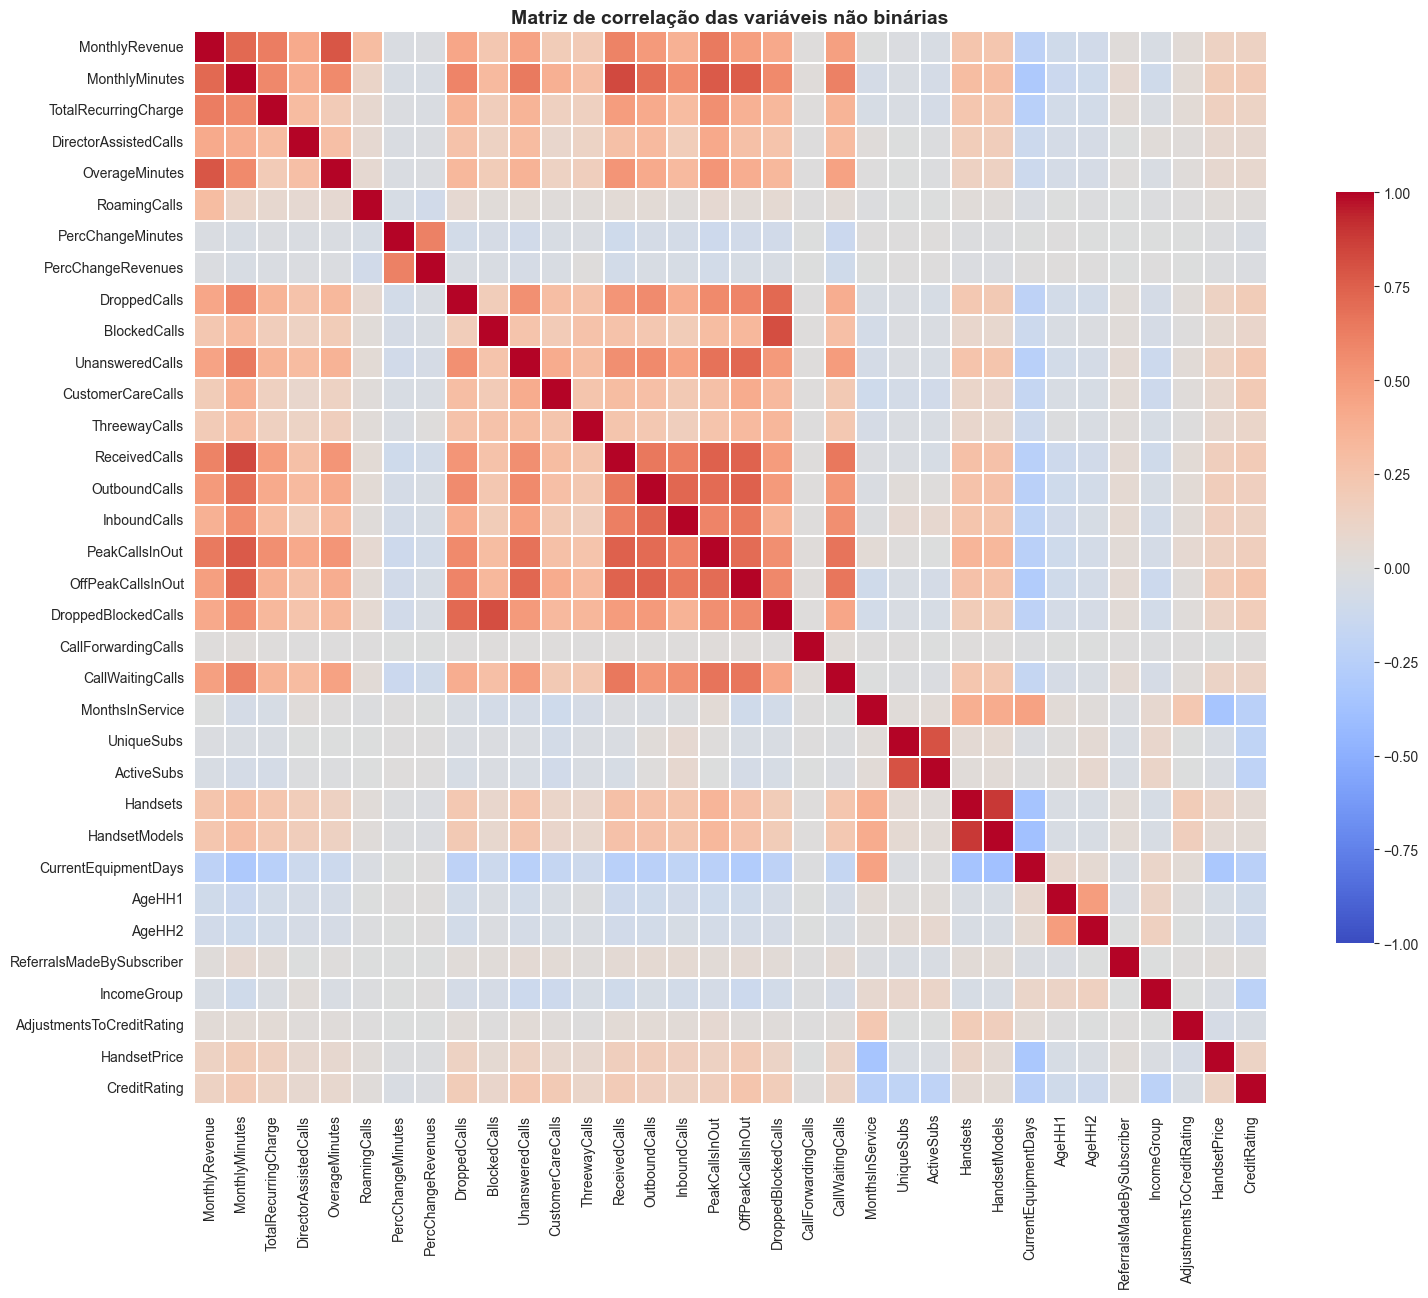

In [42]:
corr_continuas = df[colunas_continuas].corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr_continuas, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={'shrink': 0.7})
plt.title('Matriz de correlação das variáveis não binárias', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [43]:
# Pares de features com correlação forte (possível multicolinearidade)
pares = []
for i, c1 in enumerate(colunas_continuas):
    for c2 in colunas_continuas[i + 1:]:
        r = corr_continuas.loc[c1, c2]
        if abs(r) > 0.7:
            pares.append({'Feature 1': c1, 'Feature 2': c2, 'Correlação': round(r, 3)})

pares = pd.DataFrame(pares).sort_values('Correlação', ascending=False)
print(f"{len(pares)} pares com |correlação| > 0,7:\n")
print(pares.to_string(index=False))

15 pares com |correlação| > 0,7:

      Feature 1           Feature 2  Correlação
       Handsets       HandsetModels       0.888
 MonthlyMinutes       ReceivedCalls       0.829
   BlockedCalls DroppedBlockedCalls       0.816
     UniqueSubs          ActiveSubs       0.804
 MonthlyRevenue      OverageMinutes       0.788
 MonthlyMinutes      PeakCallsInOut       0.772
 MonthlyMinutes   OffPeakCallsInOut       0.765
  ReceivedCalls      PeakCallsInOut       0.747
  OutboundCalls   OffPeakCallsInOut       0.742
  ReceivedCalls   OffPeakCallsInOut       0.738
  OutboundCalls        InboundCalls       0.724
UnansweredCalls   OffPeakCallsInOut       0.720
   DroppedCalls DroppedBlockedCalls       0.715
 MonthlyRevenue      MonthlyMinutes       0.713
  OutboundCalls      PeakCallsInOut       0.710


**Conclusões da análise de correlações:**

**Correlação com o Churn:**
- **Todas as correlações são fracas:** a maior, em módulo, é de apenas 0,133. Nenhuma variável
  isolada explica o churn; o modelo precisará combinar várias delas.
- **As variáveis criadas pelo grupo estão entre as mais correlacionadas:** `Contract_Locked`
  (−0,133) e `Contract_EndWindow` (+0,115) ocupam as duas primeiras posições, à frente de qualquer
  variável original. Isso valida o feature engineering.
- **A correlação de Pearson só capta relações lineares.** `MonthsInService` tem correlação de apenas
  0,04 com o Churn, mas a análise mês a mês mostrou um padrão muito forte (pico nos meses 11 e 12).
  Uma correlação baixa não significa que a variável é inútil, e por isso foram criadas as variáveis
  da fase da fidelidade.

**Multicolinearidade:**
- **15 pares de variáveis têm correlação acima de 0,7**, quase todos entre variáveis de volume de
  uso: clientes que usam mais o serviço fazem e recebem mais chamadas de todos os tipos.
- Os pares mais fortes são `Handsets` × `HandsetModels` (0,888), `BlockedCalls` ×
  `DroppedBlockedCalls` (0,816; esta última é a soma de `DroppedCalls` e `BlockedCalls`) e
  `UniqueSubs` × `ActiveSubs` (0,804).

**Decisão:** a multicolinearidade não prejudica modelos baseados em árvores, mas torna os
coeficientes da Regressão Logística instáveis e difíceis de interpretar. `DroppedBlockedCalls` é
candidata à remoção, por ser uma soma exata de outras duas variáveis. As demais são mantidas nesta
etapa, e o efeito da remoção de variáveis redundantes será avaliado na modelagem.

# Divisão treino/teste

A base é dividida em treino (80%) e teste (20%), de forma estratificada para manter a proporção
de churn nos dois conjuntos. O conjunto de teste fica **reservado** até a avaliação final do modelo
campeão; todas as comparações entre modelos são feitas com validação cruzada sobre o treino.

A imputação dos valores ausentes **não** é feita aqui: ela faz parte do pipeline de cada modelo.
Assim, em cada rodada da validação cruzada, a mediana é calculada apenas com os dados de treino
daquela rodada, sem vazamento de informação.

In [44]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X = df.drop(columns=['Churn'])
y = df['Churn']

# Split estratificado: mantém a proporção de churn (~29%) nos dois conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Treino: {X_train.shape} | Churn: {y_train.mean():.1%}")
print(f"Teste:  {X_test.shape}  | Churn: {y_test.mean():.1%}")
print(f"\nValores ausentes no treino (serão imputados no pipeline): {X_train.isna().sum().sum():,}")

Treino: (40836, 101) | Churn: 28.8%
Teste:  (10209, 101)  | Churn: 28.8%

Valores ausentes no treino (serão imputados no pipeline): 58,542


# Baseline

## Métricas de avaliação

- **Métrica técnica principal: AUC-ROC.** Mede a capacidade do modelo de ordenar os clientes por
  risco, independentemente do limiar de decisão. É adequada para bases desbalanceadas.
- **Métricas complementares:** Recall (proporção dos clientes que cancelaram e que o modelo
  identificou), Precisão (proporção dos clientes apontados como risco que de fato cancelaram),
  F1 e PR-AUC (área sob a curva precisão-recall, mais sensível à classe minoritária).
- **A acurácia é apresentada apenas como referência**, pois é enganosa nesta base: um modelo que
  prevê "não cancela" para todos acerta 71% dos casos.

## Modelos de referência

1. **Dummy Classifier:** sempre prevê a classe majoritária ("não churn"). É o piso: qualquer modelo
   útil precisa superá-lo.
2. **Regressão Logística:** Por ser um modelo linear simples e
   interpretável, é a referência que os modelos mais complexos (Random Forest e MLP) precisarão
   superar.

Os dois são avaliados com **validação cruzada estratificada de 5 partes** sobre o conjunto de
treino. Cada modelo é um `Pipeline` com as etapas:

| Etapa | Função |
|---|---|
| `SimpleImputer(strategy='median')` | Preenche os valores ausentes com a mediana do treino |
| `StandardScaler()` | Padroniza as variáveis (média 0, desvio 1); necessário para a Regressão Logística |
| `LogisticRegression(class_weight='balanced')` | Dá mais peso à classe minoritária (churn) durante o treinamento |

In [45]:
# Validação cruzada

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

metricas = {
    'AUC-ROC': 'roc_auc',
    'PR-AUC': 'average_precision',
    'Recall': 'recall',
    'Precisão': 'precision',
    'F1': 'f1',
    'Acurácia': 'accuracy',
}

modelos = {
    'Dummy (sempre "não churn")': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('modelo', DummyClassifier(strategy='most_frequent')),
    ]),
    'Regressão Logística': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('modelo', LogisticRegression(class_weight='balanced', max_iter=1000,
                                      random_state=RANDOM_STATE)),
    ]),
}

resultados = []
for nome, pipeline in modelos.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=metricas)
    linha = {'Modelo': nome}
    for m in metricas:
        valores = scores[f'test_{m}']
        linha[m] = f"{valores.mean():.3f} ± {valores.std():.3f}"
    resultados.append(linha)

resultados_baseline = pd.DataFrame(resultados).set_index('Modelo').T
resultados_baseline

Modelo,"Dummy (sempre ""não churn"")",Regressão Logística
AUC-ROC,0.500 ± 0.000,0.652 ± 0.004
PR-AUC,0.288 ± 0.000,0.413 ± 0.008
Recall,0.000 ± 0.000,0.646 ± 0.012
Precisão,0.000 ± 0.000,0.380 ± 0.004
F1,0.000 ± 0.000,0.479 ± 0.006
Acurácia,0.712 ± 0.000,0.595 ± 0.003


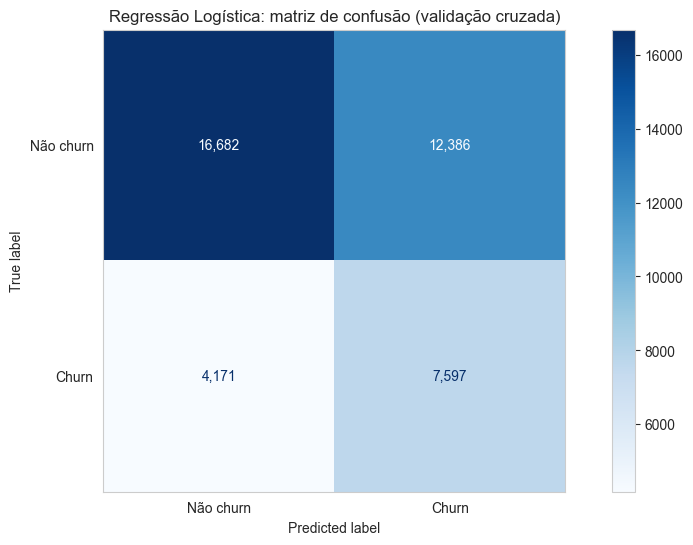

              precision    recall  f1-score   support

   Não churn      0.800     0.574     0.668     29068
       Churn      0.380     0.646     0.479     11768

    accuracy                          0.595     40836
   macro avg      0.590     0.610     0.573     40836
weighted avg      0.679     0.595     0.614     40836



In [46]:
# Matriz de confusão

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Previsões "fora da amostra": cada cliente é previsto pelo modelo que não o viu no treino
y_pred_cv = cross_val_predict(modelos['Regressão Logística'], X_train, y_train, cv=cv)

ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred_cv, display_labels=['Não churn', 'Churn'], cmap='Blues', values_format=','
)
plt.title('Regressão Logística: matriz de confusão (validação cruzada)')
plt.grid(False)
plt.show()

print(classification_report(y_train, y_pred_cv, target_names=['Não churn', 'Churn'], digits=3))

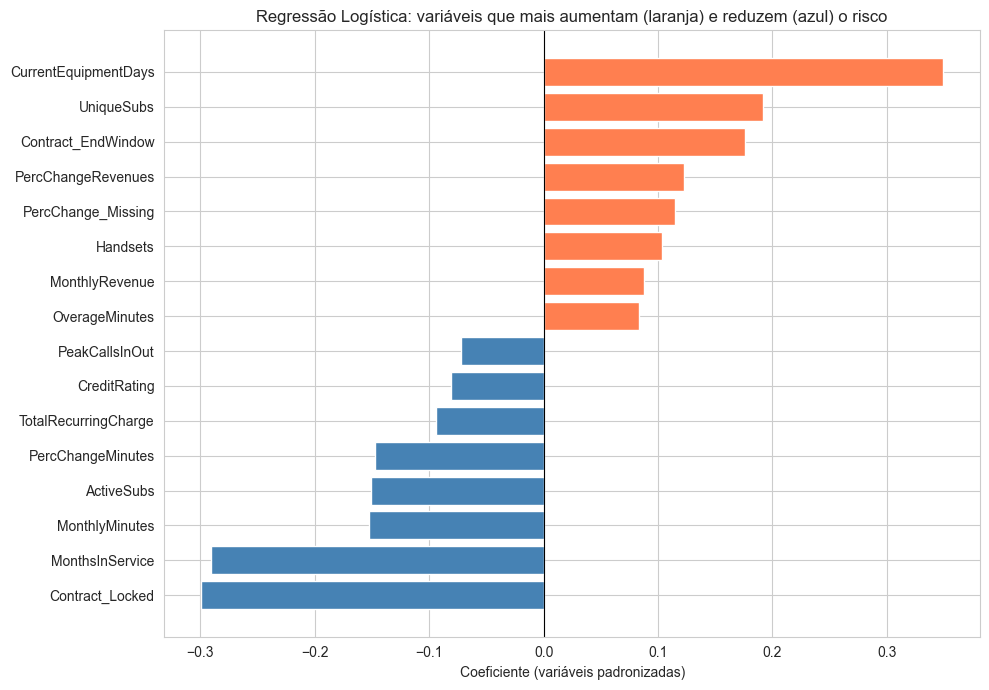

In [47]:
# Treina no treino completo para inspecionar os coeficientes
baseline_lr = modelos['Regressão Logística'].fit(X_train, y_train)

coeficientes = pd.Series(
    baseline_lr.named_steps['modelo'].coef_[0], index=X_train.columns
).sort_values()

top_coef = pd.concat([coeficientes.head(8), coeficientes.tail(8)])
cores = ['steelblue' if v < 0 else 'coral' for v in top_coef]

plt.figure(figsize=(10, 7))
plt.barh(top_coef.index, top_coef.values, color=cores)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coeficiente (variáveis padronizadas)')
plt.title('Regressão Logística: variáveis que mais aumentam (laranja) e reduzem (azul) o risco')
plt.tight_layout()
plt.show()

## Resultados do baseline

| Métrica | Dummy | Regressão Logística |
|---|---|---|
| AUC-ROC | 0,500 | **0,652** |
| PR-AUC | 0,288 | **0,413** |
| Recall | 0,000 | **0,646** |
| Precisão | 0,000 | 0,380 |
| F1 | 0,000 | 0,479 |
| Acurácia | **0,712** | 0,595 |

**Interpretação:**

- **O Dummy confirma que a acurácia engana:** ele tem a maior acurácia (71,2%) sem identificar
  nenhum cliente que cancela (Recall = 0).
- **A Regressão Logística identifica 64,6% dos clientes que cancelam** (7.597 dos 11.768 no
  treino). O custo é a precisão de 38%: para cada cliente em risco identificado corretamente,
  cerca de 1,6 cliente que não cancelaria também é apontado. Esse equilíbrio é coerente com o
  objetivo de negócio, pois deixar de identificar um cliente que vai sair custa muito mais do que
  oferecer um desconto desnecessário.
- **AUC-ROC de 0,652:** o modelo separa as classes significativamente melhor que o acaso (0,5),
  mas há espaço para melhoria. Isso é esperado, pois a análise de correlação mostrou que nenhuma
  variável tem relação linear forte com o churn (máximo de 0,133).
- **O modelo é estável:** o desvio padrão entre as 5 rodadas da validação cruzada é inferior a
  0,01 na AUC-ROC.

**Variáveis mais relevantes:** as que mais aumentam o risco são `CurrentEquipmentDays` (aparelho
antigo), `UniqueSubs` e `Contract_EndWindow` (fim da fidelidade); as que mais reduzem são
`Contract_Locked` (período de fidelidade), `MonthsInService` e `MonthlyMinutes`. Duas das cinco
mais importantes foram criadas no feature engineering, o que confirma o valor da análise da fase
contratual.

**Próximos passos (Etapa 2):** Random Forest e MLP devem superar a AUC-ROC de 0,652 na mesma
validação cruzada. Modelos não lineares podem capturar padrões que a Regressão Logística não
representa, como o pico de churn nos meses 11 e 12. O conjunto de teste permanece reservado para
a comparação final entre o modelo campeão e este baseline.

# Etapa 2: modelagem

Fluxo desta etapa (tudo medido por validação cruzada no **treino**; o teste só é usado uma vez, no fim):

1. **Pipeline sklearn** único: imputação (mediana) → padronização → **seleção de features** → modelo;
2. Treino de **Random Forest, LightGBM, XGBoost e MLP**, cada um **com e sem** seleção de features;
3. **Validação cruzada estratificada (5 folds)** e comparação pelas métricas definidas no baseline
   (principal: **AUC-ROC**);
4. Escolha do **modelo campeão**;
5. **Tuning bayesiano** (Optuna/TPE) do campeão, incluindo o limiar do seletor de features;
6. Avaliação final no teste e registro do modelo.

Todos os experimentos são registrados no **MLflow** (`mlflow ui --backend-store-uri sqlite:///mlflow.db`).

**Seleção de features:** `SelectFromModel` com um LightGBM auxiliar, que mantém as variáveis com importância
acima de um limiar. Fica **dentro do pipeline**, então é reajustada em cada fold da validação cruzada
(sem vazamento de informação).

In [48]:
import mlflow, optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score, f1_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("churn-cell2cell")


SCORING = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'recall': 'recall',
           'precision': 'precision', 'f1': 'f1', 'accuracy': 'accuracy'}

# Peso da classe churn para o XGBoost (RF e LightGBM usam class_weight)
SPW = (y_train == 0).sum() / (y_train == 1).sum()

# (classe, parâmetros fixos). n_jobs=1: o paralelismo fica nos folds da validação cruzada.
MODELOS = {
    'Random Forest': (
        RandomForestClassifier, 
        dict(class_weight='balanced_subsample', min_samples_leaf=20,
                n_jobs=1, random_state=RANDOM_STATE)
    ),
    'LightGBM': (
        LGBMClassifier, 
        dict(class_weight='balanced', n_jobs=1, verbose=-1,
                random_state=RANDOM_STATE)
    ),
    'XGBoost': (
        XGBClassifier, 
        dict(scale_pos_weight=SPW, tree_method='hist', n_jobs=1,
            random_state=RANDOM_STATE)),
    'MLP': (MLPClassifier, 
            dict(hidden_layer_sizes=(64, 32), early_stopping=True, 
                 max_iter=200, random_state=RANDOM_STATE)
    ),
}


def make_pipeline(nome, selecionar=True, threshold='median', **params):
    """Imputer -> scaler -> seletor de features (opcional) -> modelo."""
    classe, fixos = MODELOS[nome]
    seletor = SelectFromModel(
        LGBMClassifier(n_estimators=200, class_weight='balanced', n_jobs=1, verbose=-1,
                       random_state=RANDOM_STATE),
        threshold=threshold,
    ) if selecionar else 'passthrough'
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),          # necessário para o MLP
        ('selector', seletor),
        ('modelo', classe(**{**fixos, **params})),
    ]).set_output(transform='pandas')          # mantém os nomes das colunas até o seletor

2026/10/18 20:30:08 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/18 20:30:08 INFO mlflow.store.db.utils: Updating database tables
2026/10/18 20:30:09 INFO mlflow.tracking.fluent: Experiment with name 'churn-cell2cell' does not exist. Creating a new experiment.


## Validação cruzada e comparação dos modelos

Cada combinação (modelo × com/sem seleção de features) é avaliada com os mesmos 5 folds do baseline e
registrada como um *run* no MLflow. Parâmetros dos modelos: padrões razoáveis, **sem tuning** (o tuning vem depois,
só para o campeão).

In [49]:
def cv_logado(run_name, pipe, params, tags=None):
    """Validação cruzada (5 folds) + registro de parâmetros e métricas no MLflow."""
    with mlflow.start_run(run_name=run_name, nested=mlflow.active_run() is not None):
        scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
        mlflow.log_params(params)
        mlflow.set_tags(tags or {})
        res = {m: scores[f'test_{m}'] for m in SCORING}
        for m, v in res.items():
            mlflow.log_metric(f'cv_{m}_mean', v.mean())
            mlflow.log_metric(f'cv_{m}_std', v.std())
        mlflow.log_metric('fit_time_mean_s', scores['fit_time'].mean())
    return res


linhas = []
for nome in MODELOS:
    for selecionar in (False, True):
        res = cv_logado(
            f"{nome} | selecao={'sim' if selecionar else 'nao'}",
            make_pipeline(nome, selecionar),
            {'modelo': nome, 'selecao_features': selecionar},
            {'etapa': 'comparacao_cv'},
        )
        linhas.append({'Modelo': nome, 'Seleção': 'sim' if selecionar else 'não',
                       **{m: res[m].mean() for m in SCORING},
                       'AUC std': res['roc_auc'].std()})

comparacao = pd.DataFrame(linhas).sort_values('roc_auc', ascending=False).reset_index(drop=True)
comparacao.round(3)

,Modelo,Seleção,roc_auc,pr_auc,recall,precision,f1,accuracy,AUC std
0,LightGBM,não,0.679,0.457,0.620,0.407,0.491,0.630,0.004
1,LightGBM,sim,0.678,0.455,0.619,0.405,0.489,0.628,0.004
2,Random Forest,sim,0.671,0.444,0.513,0.421,0.463,0.656,0.002
3,Random Forest,não,0.668,0.441,0.526,0.415,0.464,0.650,0.002
4,XGBoost,não,0.659,0.440,0.534,0.412,0.465,0.646,0.005
5,XGBoost,sim,0.656,0.434,0.519,0.409,0.457,0.645,0.010
6,MLP,sim,0.641,0.405,0.097,0.495,0.161,0.711,0.008
7,MLP,não,0.632,0.392,0.046,0.491,0.083,0.711,0.006


## Modelo campeão

Critério: **maior AUC-ROC médio na validação cruzada** (métrica principal definida no baseline). As demais
métricas (PR-AUC, Recall, Precisão, F1) servem de desempate e de checagem de coerência com o objetivo de negócio
(identificar quem vai cancelar).

In [50]:
campeao = comparacao.iloc[0]
NOME_CAMPEAO = campeao['Modelo']
print(f"Campeão: {NOME_CAMPEAO} (seleção de features: {campeao['Seleção']})")
print(f"AUC-ROC CV = {campeao['roc_auc']:.3f} ± {campeao['AUC std']:.3f}  |  baseline (Regressão Logística) = 0,652")

# Efeito da seleção de features no AUC-ROC, por modelo
ganho = comparacao.pivot(index='Modelo', columns='Seleção', values='roc_auc')
ganho['ganho_selecao'] = ganho['sim'] - ganho['não']
ganho.round(4)

Campeão: LightGBM (seleção de features: não)
AUC-ROC CV = 0.679 ± 0.004  |  baseline (Regressão Logística) = 0,652


Seleção,não,sim,ganho_selecao
Modelo,,,
LightGBM,0.6791,0.6782,-0.0010
MLP,0.6316,0.6406,0.0089
Random Forest,0.6683,0.6712,0.0029
XGBoost,0.6595,0.6555,-0.0040


## Tuning de hiperparâmetros: busca bayesiana (Optuna/TPE)

Só o campeão é ajustado. O **TPE** modela quais regiões do espaço de busca dão bons resultados e sorteia
as próximas tentativas nelas, o que é mais eficiente que grid ou busca aleatória. O limiar do seletor de
features entra no espaço de busca junto com os hiperparâmetros do modelo.

Para ser rápido, cada tentativa usa CV de 3 folds; o resultado final é reavaliado com os 5 folds, para
comparar de forma justa com a tabela anterior. Cada tentativa é um *run* filho no MLflow.

In [51]:
N_TRIALS = 25

ESPACOS = {
    'Random Forest': lambda t: dict(
        n_estimators=t.suggest_int('n_estimators', 100, 400),
        max_depth=t.suggest_int('max_depth', 4, 20),
        min_samples_leaf=t.suggest_int('min_samples_leaf', 5, 100, log=True),
        max_features=t.suggest_categorical('max_features', ['sqrt', 'log2', 0.3])),
    'LightGBM': lambda t: dict(
        n_estimators=t.suggest_int('n_estimators', 100, 600),
        learning_rate=t.suggest_float('learning_rate', 0.01, 0.2, log=True),
        num_leaves=t.suggest_int('num_leaves', 15, 127),
        min_child_samples=t.suggest_int('min_child_samples', 20, 200),
        subsample=t.suggest_float('subsample', 0.6, 1.0), subsample_freq=1,
        colsample_bytree=t.suggest_float('colsample_bytree', 0.5, 1.0),
        reg_lambda=t.suggest_float('reg_lambda', 1e-3, 10, log=True)),
    'XGBoost': lambda t: dict(
        n_estimators=t.suggest_int('n_estimators', 100, 600),
        learning_rate=t.suggest_float('learning_rate', 0.01, 0.2, log=True),
        max_depth=t.suggest_int('max_depth', 3, 9),
        min_child_weight=t.suggest_int('min_child_weight', 1, 20),
        subsample=t.suggest_float('subsample', 0.6, 1.0),
        colsample_bytree=t.suggest_float('colsample_bytree', 0.5, 1.0),
        reg_lambda=t.suggest_float('reg_lambda', 1e-3, 10, log=True)),
    'MLP': lambda t: dict(
        hidden_layer_sizes={'64': (64,), '128': (128,), '64-32': (64, 32), '128-64': (128, 64)}[
            t.suggest_categorical('hidden', ['64', '128', '64-32', '128-64'])],
        alpha=t.suggest_float('alpha', 1e-5, 1e-1, log=True),
        learning_rate_init=t.suggest_float('learning_rate_init', 1e-4, 1e-2, log=True)),
}


def tunar(nome, n_trials=N_TRIALS):
    cv_rapido = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

    def objetivo(trial):
        threshold = trial.suggest_categorical('threshold', ['0.5*mean', 'mean', 'median'])
        params = ESPACOS[nome](trial)
        trial.set_user_attr('params', params)
        pipe = make_pipeline(nome, True, threshold, **params)
        with mlflow.start_run(run_name=f'{nome} | trial {trial.number}', nested=True):
            auc = cross_val_score(pipe, X_train, y_train, cv=cv_rapido, scoring='roc_auc', n_jobs=-1).mean()
            mlflow.log_params({**params, 'threshold': threshold})
            mlflow.log_metric('cv3_roc_auc_mean', auc)
        return auc

    with mlflow.start_run(run_name=f'{nome} | optuna'):
        mlflow.set_tags({'etapa': 'tuning_bayesiano'})
        study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
        study.optimize(objetivo, n_trials=n_trials)
        mlflow.log_metric('best_cv3_roc_auc', study.best_value)
    return study


study = tunar(NOME_CAMPEAO)
melhor = study.best_trial
print(f"Melhor AUC-ROC (CV 3 folds): {study.best_value:.4f}")
print("Limiar do seletor:", melhor.params['threshold'])
print("Hiperparâmetros:", melhor.user_attrs['params'])

Melhor AUC-ROC (CV 3 folds): 0.6799
Limiar do seletor: median
Hiperparâmetros: {'n_estimators': 278, 'learning_rate': 0.023200867504756827, 'num_leaves': 76, 'min_child_samples': 45, 'subsample': 0.9208787923016158, 'subsample_freq': 1, 'colsample_bytree': 0.5372753218398854, 'reg_lambda': 8.862326508576253}


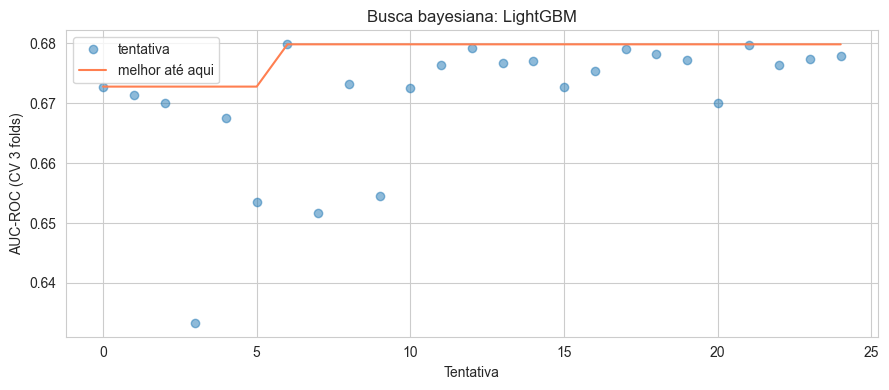

In [52]:
# Convergência da busca: AUC de cada tentativa e melhor valor acumulado
vals = [t.value for t in study.trials]
plt.figure(figsize=(9, 4))
plt.plot(vals, 'o', alpha=0.5, label='tentativa')
plt.plot(np.maximum.accumulate(vals), color='coral', label='melhor até aqui')
plt.xlabel('Tentativa'); plt.ylabel('AUC-ROC (CV 3 folds)'); plt.legend()
plt.title(f'Busca bayesiana: {NOME_CAMPEAO}')
plt.tight_layout(); plt.show()

## Avaliação final do campeão

1. Reavalia o modelo ajustado com os **mesmos 5 folds** da comparação (comparação justa com os defaults);
2. Treina no treino completo e avalia **uma única vez no teste**;
3. Registra métricas e o modelo no MLflow.

In [ ]:
params_otimos = melhor.user_attrs['params']
threshold_otimo = melhor.params['threshold']
pipe_final = make_pipeline(NOME_CAMPEAO, True, threshold_otimo, **params_otimos)

with mlflow.start_run(run_name=f'CAMPEAO | {NOME_CAMPEAO} (tunado)'):
    mlflow.set_tags({'etapa': 'campeao'})
    mlflow.log_params({'modelo': NOME_CAMPEAO, 'threshold': threshold_otimo, **params_otimos})

    # 1) CV com 5 folds, comparável à tabela da comparação
    scores = cross_validate(pipe_final, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    cv_final = {m: scores[f'test_{m}'] for m in SCORING}
    for m, v in cv_final.items():
        mlflow.log_metric(f'cv_{m}_mean', v.mean())
        mlflow.log_metric(f'cv_{m}_std', v.std())

    # 2) Ajuste no treino completo + avaliação única no teste
    pipe_final.fit(X_train, y_train)
    proba = pipe_final.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    teste = {'roc_auc': roc_auc_score(y_test, proba), 'pr_auc': average_precision_score(y_test, proba),
             'recall': recall_score(y_test, pred), 'precision': precision_score(y_test, pred),
             'f1': f1_score(y_test, pred)}
    for m, v in teste.items():
        mlflow.log_metric(f'test_{m}', v)

    # 3) Modelo (pipeline completo, com imputer, scaler e seletor)
    mlflow.sklearn.log_model(pipe_final, name='modelo', serialization_format='cloudpickle')

resumo = pd.DataFrame({
    'CV 5 folds (default)': campeao[list(SCORING)].astype(float),
    'CV 5 folds (tunado)': {m: v.mean() for m, v in cv_final.items()},
    'Teste (tunado)': teste,
}).round(3)
resumo

2026/10/18 20:34:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,CV 5 folds (default),CV 5 folds (tunado),Teste (tunado)
accuracy,0.630,0.639,NaN
f1,0.491,0.490,0.495
pr_auc,0.457,0.460,0.458
precision,0.407,0.413,0.411
recall,0.620,0.603,0.623
roc_auc,0.679,0.682,0.682


52 de 101 features mantidas (limiar = median)

Removidas (49): ['AdjustmentsToCreditRating', 'CallForwardingCalls', 'Contract_Locked', 'HandsetPrice_Unknown', 'HasCreditCard', 'Homeownership', 'NonUSTravel', 'Occupation_Clerical', 'Occupation_Crafts', 'Occupation_Homemaker', 'Occupation_Professional', 'Occupation_Retired', 'Occupation_Self', 'Occupation_Student', 'OptOutMailings', 'OwnsComputer', 'OwnsMotorcycle', 'RVOwner', 'ReferralsMadeBySubscriber', 'ServiceRegion_AIR', 'ServiceRegion_ATL', 'ServiceRegion_BOS', 'ServiceRegion_CHI', 'ServiceRegion_DAL', 'ServiceRegion_DEN', 'ServiceRegion_DET', 'ServiceRegion_FLN', 'ServiceRegion_HAR', 'ServiceRegion_HOU', 'ServiceRegion_KCY', 'ServiceRegion_LAX', 'ServiceRegion_MIL', 'ServiceRegion_MIN', 'ServiceRegion_NCR', 'ServiceRegion_NEV', 'ServiceRegion_NMX', 'ServiceRegion_NNY', 'ServiceRegion_NYC', 'ServiceRegion_OHI', 'ServiceRegion_OKC', 'ServiceRegion_OMA', 'ServiceRegion_Other', 'ServiceRegion_PHI', 'ServiceRegion_PHX', 'ServiceRegion_

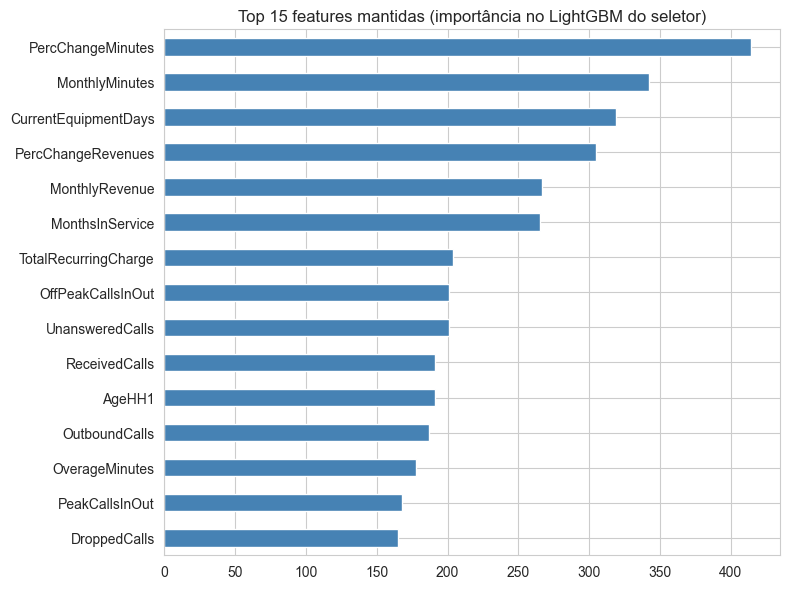

In [54]:
# Features escolhidas pelo seletor e as mais importantes
sel = pipe_final.named_steps['selector']
escolhidas = pipe_final[:-1].get_feature_names_out()
print(f"{len(escolhidas)} de {X_train.shape[1]} features mantidas (limiar = {threshold_otimo})")

removidas = sorted(set(X_train.columns) - set(escolhidas))
print(f"\nRemovidas ({len(removidas)}):", removidas)

imp = pd.Series(sel.estimator_.feature_importances_, index=X_train.columns)
imp[escolhidas].sort_values().tail(15).plot(kind='barh', figsize=(8, 6), color='steelblue')
plt.title('Top 15 features mantidas (importância no LightGBM do seletor)')
plt.tight_layout(); plt.show()

## Como consultar os experimentos

```
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

Abra http://127.0.0.1:5000, experimento **churn-cell2cell**. Filtre pela tag `etapa`
(`comparacao_cv`, `tuning_bayesiano`, `campeao`) e ordene por `cv_roc_auc_mean`.